# Steel Surface Defect Inspection — Classification, Detection and Segmentation on NEU-DET
### EfficientNet-B0 (transfer learning) · classical heads (LogReg / RF / XGBoost) · YOLOv8 · SAM2 · Explainability · Robustness · Deployment

**Goal.** Build an end-to-end, *honestly evaluated* visual-inspection pipeline for hot-rolled steel strips (6 defect classes: crazing, inclusion, patches, pitted surface, rolled-in scale, scratches) — the same building blocks used in industrial and automotive perception stacks (CNN backbone → lightweight head → detector → promptable segmenter → explainability).

**What this notebook delivers**

| Block | Question answered | Output |
|---|---|---|
| 1. Data audit | Is the data clean? Any duplicates / leakage between splits? | integrity + duplicate report, class balance, intensity stats |
| 2. Classification — official split | How good is each model when selected on *validation* and tested *once*? | metrics + bootstrap 95 % CI, ablation vs. frozen ImageNet features |
| 3. Classification — leak-free nested CV | What is the *defensible* headline number? | 5-fold mean ± std, pooled OOF CI, McNemar tests, calibration (ECE) |
| 4. Error analysis, Grad-CAM, SHAP | Where and why does it fail? | confusion pairs, confident errors, saliency maps |
| 5. Robustness + efficiency | Does it survive noise / blur / lighting? How fast is it? | degradation curves, params, size, latency |
| 6. Detection — YOLOv8 | Can we localise defects? | mAP50 / mAP50-95 / P / R per class, operating threshold from validation, image-level accuracy, latency |
| 7. Segmentation — SAM2 | Can boxes become masks? | masks + *proxy* quality metrics (no GT masks exist) |
| 8. End-to-end + deployment | Can it be served? | `inspect_image()`, `deployment/` folder + zip, `results.json` |

**How to run on Kaggle:** Settings → *Accelerator = GPU (T4)* · *Internet = ON* · *Add Data*: (1) `fantacher/neu-metal-surface-defects-data` (classification folders `train/valid/test`) and (2) a **NEU-DET** version that contains the `ANNOTATIONS` (Pascal-VOC `.xml`) folder. Then *Run All* (≈ 35–50 min with nested CV; set `CFG.run_nested_cv = False` to skip the CV block).

**Design decisions that differ from a naive first version (and why)**
1. *Feature extraction uses a non-augmenting loader.* Heads must be trained on the same deterministic features they see at test time.
2. *Frozen blocks keep BatchNorm in eval mode* — otherwise running statistics silently drift while the weights are "frozen".
3. *Checkpoint selection on validation **loss*** (accuracy saturates at 100 % on 72 images and cannot discriminate epochs).
4. *The "best model" is chosen on validation, never on the test set.*
5. *Cross-validation re-fits the CNN inside every fold.* Pooling features from a CNN fine-tuned on all labels and then cross-validating the heads leaks label information and inflates scores.
6. *Detection split is stratified by dominant class* and the operating confidence threshold is picked on the validation split.
7. *Every number printed is also stored in `results.json`* so the README / CV cannot drift from the notebook.

In [1]:
%pip install -q ultralytics grad-cam shap xgboost

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## 0. Setup, configuration, reproducibility

In [2]:
import os, sys, gc, copy, json, time, glob, random, hashlib, shutil, platform, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter, ImageEnhance

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, log_loss)
from xgboost import XGBClassifier
from scipy.stats import binomtest

sns.set_theme(style="whitegrid", context="notebook")

@dataclass
class Config:
    seed: int = 42
    # --- classification ---
    img_size: int = 224
    batch_size: int = 32
    num_workers: int = 2
    frozen_epochs: int = 8
    finetune_epochs: int = 6
    lr_head_frozen: float = 1e-3
    lr_head_ft: float = 1e-4
    lr_backbone_ft: float = 1e-5
    weight_decay: float = 1e-4
    label_smoothing: float = 0.0
    # --- evaluation ---
    run_nested_cv: bool = True      # set False to skip the (slow) leak-free CV block
    n_folds: int = 5
    inner_val_frac: float = 0.10    # validation share carved out of each CV-train fold (checkpoint selection)
    bootstrap_n: int = 2000
    shap_n: int = 200
    # --- detection / segmentation ---
    yolo_model: str = "yolov8n.pt"
    yolo_epochs: int = 60
    yolo_patience: int = 15
    yolo_imgsz: int = 640
    yolo_batch: int = 16
    sam_weights: str = "sam2.1_t.pt"
    sam_eval_images: int = 60

CFG = Config()
SEED = CFG.seed

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

RESULTS = {"config": asdict(CFG)}   # every headline number lands here -> results.json

def jsonable(o):
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, pd.DataFrame): return jsonable(o.to_dict(orient="records"))
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    return o

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=150, bbox_inches="tight")

print(f"python {platform.python_version()} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

python 3.13.15 | torch 2.11.0+cu128 | device cuda (Tesla T4)


## 1. Data audit (EDA, integrity, leakage checks)

Before modelling we verify: file integrity, image size/mode, class balance, **exact duplicates** (inside a split and — more importantly — *across* splits, which would silently inflate test scores) and per-class intensity statistics (an easy way to see whether a trivial brightness cue separates classes).

ROOT: /kaggle/input/datasets/muamarjasim/neu-metal-surface-defect-dataset/NEU Metal Surface Defects Data
Classes: ['Crazing', 'Inclusion', 'Patches', 'Pitted', 'Rolled', 'Scratches']
{'test': 72, 'train': 1656, 'valid': 72} | total: 1800
{
  "n_images": 1800,
  "corrupted_files": 0,
  "unique_image_sizes": [
    "(200, 200)"
  ],
  "duplicate_groups": 1,
  "duplicate_groups_across_splits": 0,
  "duplicate_groups_with_conflicting_labels": 0,
  "images_per_class": {
    "Crazing": 300,
    "Inclusion": 300,
    "Patches": 300,
    "Pitted": 300,
    "Rolled": 300,
    "Scratches": 300
  }
}


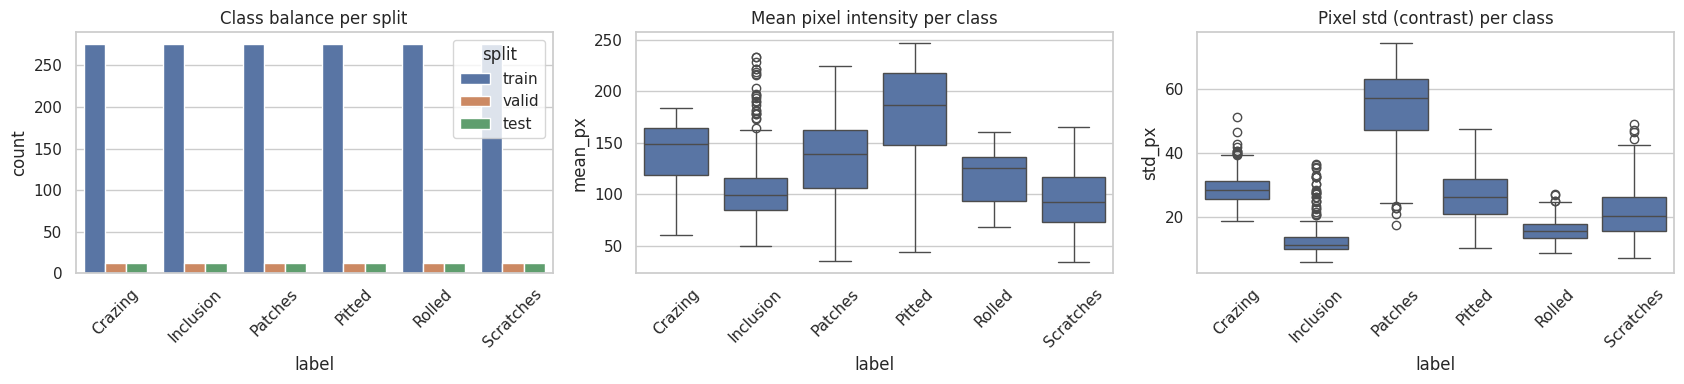

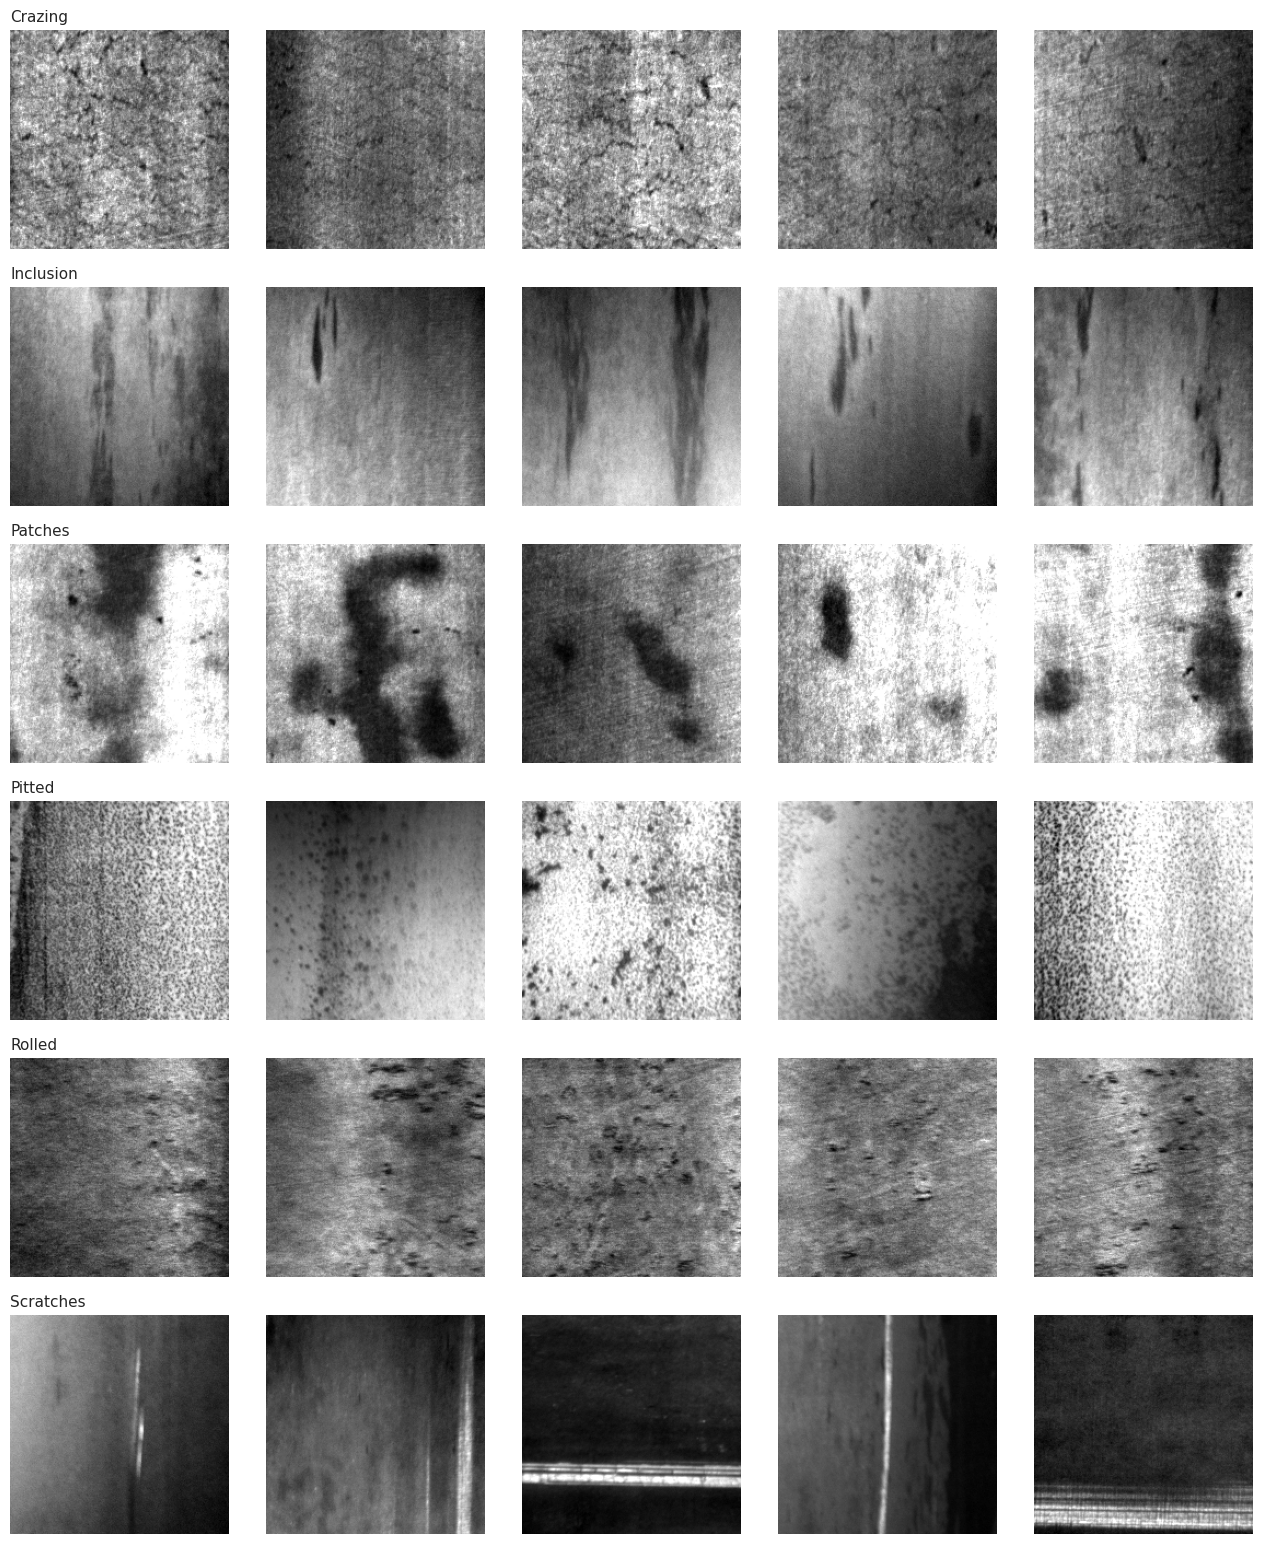

In [3]:
# --- locate the classification dataset (folders train/valid/test with one sub-folder per class) ---
def find_dataset_root(base="/kaggle/input", required=("train", "valid", "test")):
    for dirpath, dirnames, _ in os.walk(base):
        if all(r in {d.lower() for d in dirnames} for r in required):
            return dirpath
    raise FileNotFoundError("No folder with train/valid/test found. Add 'neu-metal-surface-defects-data' to the notebook.")

def resolve_split_dir(root, name):
    for d in os.listdir(root):
        if d.lower() == name: return os.path.join(root, d)
    raise FileNotFoundError(name)

ROOT = find_dataset_root()
SPLIT_DIRS = {s: resolve_split_dir(ROOT, s) for s in ("train", "valid", "test")}
CLASSES = sorted(d for d in os.listdir(SPLIT_DIRS["train"]) if os.path.isdir(os.path.join(SPLIT_DIRS["train"], d)))
NUM_CLASSES = len(CLASSES)
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
print("ROOT:", ROOT); print("Classes:", CLASSES)

def build_index(split_dir, split_name):
    rows = []
    for cls in CLASSES:
        d = os.path.join(split_dir, cls)
        if not os.path.isdir(d): continue
        for f in sorted(os.listdir(d)):
            if f.lower().endswith((".bmp", ".jpg", ".jpeg", ".png")):
                rows.append({"filepath": os.path.join(d, f), "label": cls, "split": split_name})
    return pd.DataFrame(rows)

all_df = pd.concat([build_index(p, s) for s, p in SPLIT_DIRS.items()], ignore_index=True)
all_df["y"] = all_df.label.map(class_to_idx)
print(all_df.groupby("split").size().to_dict(), "| total:", len(all_df))

# --- integrity, size, duplicates ---
def md5(fp):
    with open(fp, "rb") as f: return hashlib.md5(f.read()).hexdigest()

bad, sizes, stats = [], [], []
for fp in all_df.filepath:
    try:
        with Image.open(fp) as im:
            sizes.append(im.size); g = np.asarray(im.convert("L"), dtype=np.float32)
            stats.append((g.mean(), g.std()))
    except Exception:
        bad.append(fp); sizes.append((0, 0)); stats.append((np.nan, np.nan))
all_df["md5"] = all_df.filepath.map(md5)
all_df[["mean_px", "std_px"]] = np.array(stats)

g = all_df.groupby("md5").agg(n=("md5", "size"), n_splits=("split", "nunique"), n_labels=("label", "nunique"))
audit = {
    "n_images": int(len(all_df)), "corrupted_files": len(bad), "unique_image_sizes": sorted({str(s) for s in sizes}),
    "duplicate_groups": int((g.n > 1).sum()), "duplicate_groups_across_splits": int((g.n_splits > 1).sum()),
    "duplicate_groups_with_conflicting_labels": int((g.n_labels > 1).sum()),
    "images_per_class": all_df.label.value_counts().sort_index().to_dict(),
}
RESULTS["data_audit"] = audit
print(json.dumps(jsonable(audit), indent=2))
if audit["duplicate_groups_across_splits"] > 0:
    print("WARNING: identical images appear in several splits -> test metrics are optimistic.")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=all_df, x="label", hue="split", order=CLASSES, ax=ax[0]); ax[0].set_title("Class balance per split"); ax[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=all_df, x="label", y="mean_px", order=CLASSES, ax=ax[1]); ax[1].set_title("Mean pixel intensity per class"); ax[1].tick_params(axis="x", rotation=45)
sns.boxplot(data=all_df, x="label", y="std_px", order=CLASSES, ax=ax[2]); ax[2].set_title("Pixel std (contrast) per class"); ax[2].tick_params(axis="x", rotation=45)
savefig("01_data_audit.png"); plt.show()

fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(13, 2.6 * NUM_CLASSES))
for i, cls in enumerate(CLASSES):
    for j, fp in enumerate(all_df[all_df.label == cls].filepath.sample(5, random_state=SEED)):
        axes[i, j].imshow(Image.open(fp).convert("L"), cmap="gray"); axes[i, j].axis("off")
    axes[i, 0].set_title(cls, loc="left", fontsize=11)
savefig("02_sample_grid.png"); plt.show()

## 2. Preprocessing, datasets, model and training utilities

* Images are 200×200 grayscale → replicated to 3 channels and resized to 224 for the ImageNet-pretrained EfficientNet-B0.
* Augmentation is **geometry + mild photometric** only (defects are texture patterns; flips/rotations are label-preserving for this task).
* Training = **phase 1** (frozen backbone, train head) → **phase 2** (unfreeze blocks 7–8, small backbone LR). Checkpoints are selected on validation *loss*.

In [4]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
S = CFG.img_size
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.80, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
eval_tf = transforms.Compose([
    transforms.Resize((S, S)), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

class DefectDS(Dataset):
    def __init__(self, df, transform):
        self.paths, self.y, self.t = df.filepath.tolist(), df.y.tolist(), transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.t(Image.open(self.paths[i]).convert("RGB")), self.y[i], self.paths[i]

def make_loader(df, train=False, transform=None, batch_size=None):
    g = torch.Generator(); g.manual_seed(CFG.seed)
    return DataLoader(DefectDS(df, transform or (train_tf if train else eval_tf)),
                      batch_size=batch_size or CFG.batch_size, shuffle=train, drop_last=train,
                      num_workers=CFG.num_workers, pin_memory=DEVICE.type == "cuda",
                      generator=g if train else None)

# ---------------- model ----------------
def build_model(n_classes):
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
    return m

def make_extractor(model):
    ex = copy.deepcopy(model); ex.classifier = nn.Identity()
    return ex.eval().to(DEVICE)

def make_imagenet_extractor():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier = nn.Identity()
    return m.eval().to(DEVICE)

def set_trainable(model, backbone_blocks=()):
    for p in model.features.parameters(): p.requires_grad = False
    for b in backbone_blocks:
        for p in model.features[b].parameters(): p.requires_grad = True
    for p in model.classifier.parameters(): p.requires_grad = True

def set_train_mode(model):
    model.train()
    for blk in model.features.children():          # frozen blocks keep BN statistics fixed
        if not any(p.requires_grad for p in blk.parameters()): blk.eval()

def train_one_epoch(model, loader, opt, crit, scaler):
    set_train_mode(model); tot, correct, n = 0.0, 0, 0
    for x, y, _ in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(x); loss = crit(out, y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot / n, correct / n

@torch.no_grad()
def evaluate_epoch(model, loader, crit):
    model.eval(); tot, correct, n = 0.0, 0, 0
    for x, y, _ in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(x); loss = crit(out, y)
        tot += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot / n, correct / n

def run_phase(model, tl, vl, epochs, blocks, lr_head, lr_bb, hist, phase, verbose):
    set_trainable(model, blocks)
    groups = [{"params": list(model.classifier.parameters()), "lr": lr_head}]
    bb = [p for p in model.features.parameters() if p.requires_grad]
    if bb: groups.append({"params": bb, "lr": lr_bb})
    opt = optim.AdamW(groups, weight_decay=CFG.weight_decay)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
    crit = nn.CrossEntropyLoss(label_smoothing=CFG.label_smoothing)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, best_state = float("inf"), None
    for ep in range(epochs):
        trl, tra = train_one_epoch(model, tl, opt, crit, scaler)
        val, vaa = evaluate_epoch(model, vl, crit); sched.step()
        hist.append(dict(phase=phase, epoch=len(hist) + 1, train_loss=trl, train_acc=tra, val_loss=val, val_acc=vaa))
        if val < best: best, best_state = val, copy.deepcopy(model.state_dict())
        if verbose: print(f"[{phase}] ep {ep+1}/{epochs} | train {trl:.4f}/{tra:.3f} | val {val:.4f}/{vaa:.3f}")
    model.load_state_dict(best_state)

def fit_cnn(train_df, val_df, verbose=True, seed=SEED):
    set_seed(seed)
    model = build_model(NUM_CLASSES).to(DEVICE)
    tl, vl = make_loader(train_df, train=True), make_loader(val_df)
    hist = []
    run_phase(model, tl, vl, CFG.frozen_epochs, (), CFG.lr_head_frozen, None, hist, "frozen", verbose)
    run_phase(model, tl, vl, CFG.finetune_epochs, (7, 8), CFG.lr_head_ft, CFG.lr_backbone_ft, hist, "finetune", verbose)
    return model, pd.DataFrame(hist)

@torch.no_grad()
def predict_proba(model, df, transform=None):
    model.eval(); out = []
    for x, _, _ in make_loader(df, transform=transform):
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out.append(torch.softmax(model(x.to(DEVICE)).float(), 1).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def extract_features(extractor, df):
    feats = []
    for x, _, _ in make_loader(df):                      # deterministic: no augmentation, no shuffle
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            feats.append(extractor(x.to(DEVICE)).float().cpu().numpy())
    return np.concatenate(feats)

## 3. Evaluation toolkit

Accuracy alone is a weak summary. We report **macro-F1** (class-balanced), **balanced accuracy**, **MCC**, a **bootstrap 95 % CI**, an **exact McNemar test** for paired model comparison, and **expected calibration error (ECE)** — a model that is 99 % accurate but over-confident is hard to use in a real inspection line.

In [5]:
def clf_metrics(y, p):
    return {"accuracy": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro"),
            "balanced_acc": balanced_accuracy_score(y, p), "mcc": matthews_corrcoef(y, p)}

def bootstrap_ci(y, p, metric="accuracy", n=None, seed=0):
    rng = np.random.default_rng(seed); n = n or CFG.bootstrap_n; y, p = np.asarray(y), np.asarray(p); N = len(y); vals = []
    for _ in range(n):
        i = rng.integers(0, N, N)
        vals.append(accuracy_score(y[i], p[i]) if metric == "accuracy" else f1_score(y[i], p[i], average="macro"))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def expected_calibration_error(proba, y, n_bins=10):
    conf, pred = proba.max(1), proba.argmax(1); acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)

def mcnemar_exact(y, pa, pb):
    a, b = (pa == y), (pb == y)
    only_a, only_b = int((a & ~b).sum()), int((~a & b).sum()); n = only_a + only_b
    p = 1.0 if n == 0 else float(binomtest(min(only_a, only_b), n, 0.5).pvalue)
    return p, only_a, only_b

def plot_cm(y, p, title, fname, labels=None, normalize=True):
    labels = labels or CLASSES
    cm = confusion_matrix(y, p, labels=list(range(len(labels))), normalize="true" if normalize else None)
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False,
                                                          values_format=".2f" if normalize else "d")
    ax.set_title(title); savefig(fname); plt.show()

# ---- classical heads trained on top of CNN embeddings (1280-d) ----
HEADS = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1),
    "XGBoost": lambda: XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                     colsample_bytree=0.5, objective="multi:softprob", eval_metric="mlogloss",
                                     tree_method="hist", random_state=SEED, n_jobs=-1),
}

## 4. Classification — Experiment A: official train / valid / test split

Protocol: fit the CNN on **train**, pick checkpoints and the best fine-tuned head on **valid**, report on **test exactly once**. A frozen-ImageNet + LogReg baseline (no fine-tuning, no labels used to build the features) quantifies how much fine-tuning actually buys.

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 150MB/s]


[frozen] ep 1/8 | train 0.9458/0.870 | val 0.3852/1.000
[frozen] ep 2/8 | train 0.3329/0.972 | val 0.1590/1.000
[frozen] ep 3/8 | train 0.2071/0.982 | val 0.1006/1.000
[frozen] ep 4/8 | train 0.1593/0.982 | val 0.0725/1.000
[frozen] ep 5/8 | train 0.1288/0.988 | val 0.0623/1.000
[frozen] ep 6/8 | train 0.1196/0.990 | val 0.0541/1.000
[frozen] ep 7/8 | train 0.1101/0.991 | val 0.0519/1.000
[frozen] ep 8/8 | train 0.1124/0.987 | val 0.0509/1.000
[finetune] ep 1/6 | train 0.5246/0.887 | val 0.3250/1.000
[finetune] ep 2/6 | train 0.3290/0.956 | val 0.1962/1.000
[finetune] ep 3/6 | train 0.2331/0.969 | val 0.1486/1.000
[finetune] ep 4/6 | train 0.1903/0.977 | val 0.1180/1.000
[finetune] ep 5/6 | train 0.1853/0.974 | val 0.1120/1.000
[finetune] ep 6/6 | train 0.1807/0.975 | val 0.1111/1.000


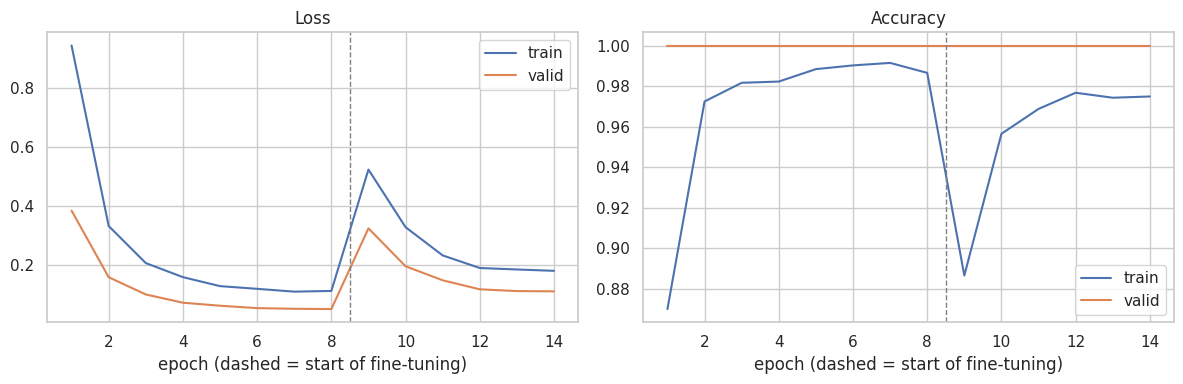

In [6]:
train_df = all_df[all_df.split == "train"].reset_index(drop=True)
valid_df = all_df[all_df.split == "valid"].reset_index(drop=True)
test_df  = all_df[all_df.split == "test"].reset_index(drop=True)
y_tr, y_va, y_te = train_df.y.values, valid_df.y.values, test_df.y.values

t0 = time.time()
model_A, hist_A = fit_cnn(train_df, valid_df, verbose=True)
RESULTS["classifier_train_time_sec"] = round(time.time() - t0, 1)
torch.save(model_A.state_dict(), OUT / "efficientnet_b0_finetuned.pt")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_A.epoch, hist_A.train_loss, label="train"); ax[0].plot(hist_A.epoch, hist_A.val_loss, label="valid"); ax[0].set_title("Loss")
ax[1].plot(hist_A.epoch, hist_A.train_acc, label="train"); ax[1].plot(hist_A.epoch, hist_A.val_acc, label="valid"); ax[1].set_title("Accuracy")
for a in ax:
    a.axvline(CFG.frozen_epochs + 0.5, color="gray", ls="--", lw=1); a.set_xlabel("epoch (dashed = start of fine-tuning)"); a.legend()
savefig("03_training_curves.png"); plt.show()

feature shapes: (1656, 1280) (72, 1280) (72, 1280)
                                     val_acc  val_macro_f1  val_logloss  test_acc  test_macro_f1  test_mcc  test_acc_CI95_lo  test_acc_CI95_hi
model                                                                                                                                         
CNN softmax (fine-tuned)                 1.0           1.0       0.1111    1.0000         1.0000    1.0000            1.0000               1.0
FT-CNN + LogReg                          1.0           1.0       0.0003    1.0000         1.0000    1.0000            1.0000               1.0
FT-CNN + RandomForest                    1.0           1.0       0.2069    1.0000         1.0000    1.0000            1.0000               1.0
FT-CNN + XGBoost                         1.0           1.0       0.0048    0.9861         0.9861    0.9836            0.9583               1.0
ImageNet-frozen + LogReg (baseline)      1.0           1.0       0.0008    1.0000         1

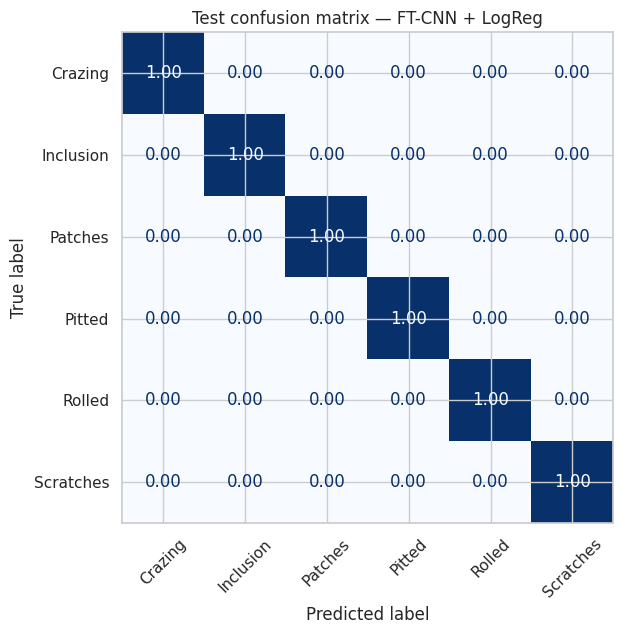

CNN softmax ECE on test: 0.1493


In [7]:
# ---- features: fine-tuned CNN (deterministic) and frozen ImageNet baseline ----
ex_A = make_extractor(model_A)
F_tr, F_va, F_te = (extract_features(ex_A, d) for d in (train_df, valid_df, test_df))

ex_in = make_imagenet_extractor()
F_in_all = extract_features(ex_in, all_df)                       # no labels involved -> no leakage, reusable in CV
m_tr, m_va, m_te = ((all_df.split == s).values for s in ("train", "valid", "test"))
F_in_tr, F_in_va, F_in_te = F_in_all[m_tr], F_in_all[m_va], F_in_all[m_te]
print("feature shapes:", F_tr.shape, F_va.shape, F_te.shape)

cands, heads_A = {}, {}
cands["CNN softmax (fine-tuned)"] = (predict_proba(model_A, valid_df), predict_proba(model_A, test_df))
for hn, fac in HEADS.items():
    clf = fac().fit(F_tr, y_tr); heads_A[hn] = clf
    cands[f"FT-CNN + {hn}"] = (clf.predict_proba(F_va), clf.predict_proba(F_te))
base = HEADS["LogReg"]().fit(F_in_tr, y_tr)
BASELINE_NAME = "ImageNet-frozen + LogReg (baseline)"
cands[BASELINE_NAME] = (base.predict_proba(F_in_va), base.predict_proba(F_in_te))

rows = []
for name, (pv, pt) in cands.items():
    mv, mt = clf_metrics(y_va, pv.argmax(1)), clf_metrics(y_te, pt.argmax(1))
    lo, hi = bootstrap_ci(y_te, pt.argmax(1), "accuracy")
    rows.append({"model": name, "val_acc": mv["accuracy"], "val_macro_f1": mv["macro_f1"],
                 "val_logloss": log_loss(y_va, pv, labels=list(range(NUM_CLASSES))),
                 "test_acc": mt["accuracy"], "test_macro_f1": mt["macro_f1"], "test_mcc": mt["mcc"],
                 "test_acc_CI95_lo": lo, "test_acc_CI95_hi": hi})
official_df = pd.DataFrame(rows).set_index("model")

# selection among fine-tuned candidates uses VALIDATION only (macro-F1, ties broken by log-loss)
sel_pool = official_df.drop(index=BASELINE_NAME)
SELECTED_A = sel_pool.sort_values(["val_macro_f1", "val_logloss"], ascending=[False, True]).index[0]
print(official_df.round(4).to_string()); print("\nSelected on validation:", SELECTED_A)
print(f"Test set has only {len(y_te)} images: 1 error = {100/len(y_te):.1f} pts. Ties at 100 % are NOT evidence of superiority.")

p_sel = cands[SELECTED_A][1].argmax(1)
print("\n" + classification_report(y_te, p_sel, target_names=CLASSES, digits=3))
plot_cm(y_te, p_sel, f"Test confusion matrix — {SELECTED_A}", "04_cm_official_test.png")

ece_A = expected_calibration_error(cands["CNN softmax (fine-tuned)"][1], y_te)
RESULTS["official_split"] = {"table": official_df.reset_index(), "selected_on_validation": SELECTED_A,
                             "cnn_softmax_ece_test": ece_A, "n_test": int(len(y_te))}
print(f"CNN softmax ECE on test: {ece_A:.4f}")

## 5. Classification — Experiment B: leak-free nested cross-validation (the headline number)

The official test split is tiny (72 images) and the CNN was fine-tuned on labels from the other splits. For a defensible estimate we pool all 1 800 images and run **stratified 5-fold CV where the CNN is re-fine-tuned inside every fold** (10 % of each training fold is held out for checkpoint selection). Heads are fitted on the fold-train embeddings and scored on the untouched fold. Out-of-fold (OOF) predictions are pooled for CIs, McNemar tests, calibration and the confusion matrix.

> Cost ≈ 5 × (14 epochs). Set `CFG.run_nested_cv = False` to skip.

fold 1/5 done in 106s | CNN acc 0.9806
fold 2/5 done in 104s | CNN acc 0.9611
fold 3/5 done in 103s | CNN acc 0.9750
fold 4/5 done in 104s | CNN acc 0.9722
fold 5/5 done in 108s | CNN acc 0.9778
                          accuracy_mean  accuracy_std  macro_f1_mean  macro_f1_std  balanced_acc_mean  balanced_acc_std  mcc_mean  mcc_std  oof_acc  oof_acc_CI95_lo  oof_acc_CI95_hi  oof_macro_f1  oof_f1_CI95_lo  oof_f1_CI95_hi  oof_errors
method                                                                                                                                                                                                                                         
FT-CNN + LogReg                  0.9989        0.0015         0.9989        0.0015             0.9989            0.0015    0.9987   0.0018   0.9989           0.9972           1.0000        0.9989          0.9971          1.0000           2
ImageNet-frozen + LogReg         0.9972        0.0020         0.9972        0.0020   

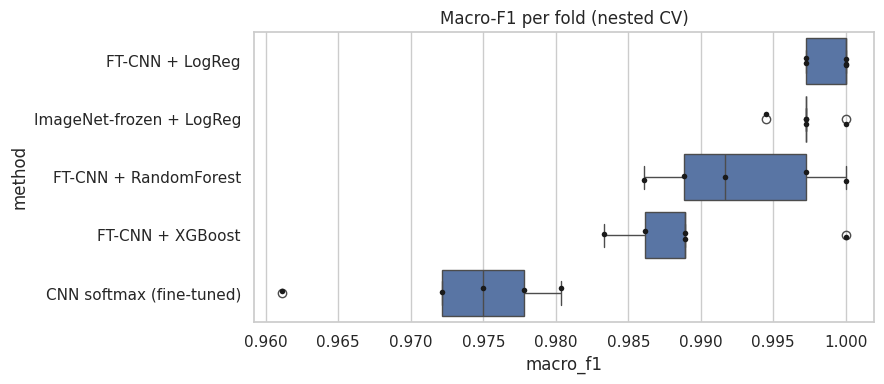

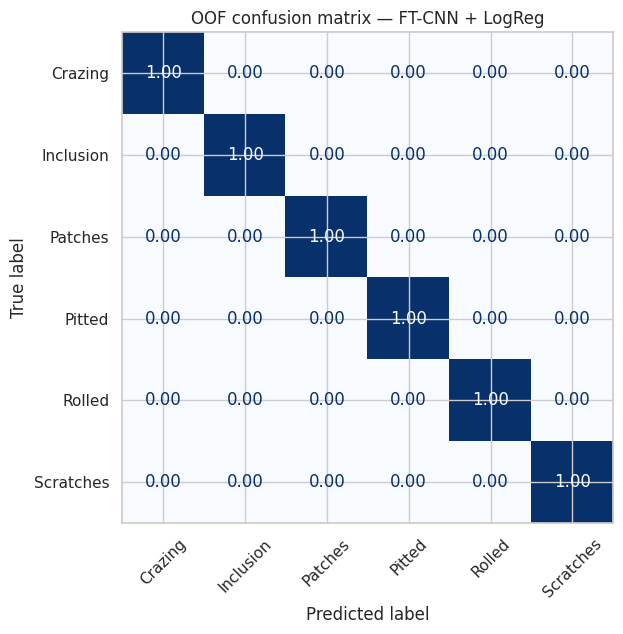

              precision    recall  f1-score   support

     Crazing      1.000     1.000     1.000       300
   Inclusion      0.997     0.997     0.997       300
     Patches      1.000     1.000     1.000       300
      Pitted      0.997     1.000     0.998       300
      Rolled      1.000     1.000     1.000       300
   Scratches      1.000     0.997     0.998       300

    accuracy                          0.999      1800
   macro avg      0.999     0.999     0.999      1800
weighted avg      0.999     0.999     0.999      1800



In [8]:
CV_DONE = False
METHODS = [BASELINE_NAME.replace(" (baseline)", ""), "CNN softmax (fine-tuned)", "FT-CNN + LogReg", "FT-CNN + RandomForest", "FT-CNN + XGBoost"]
BASE_M = METHODS[0]

if CFG.run_nested_cv:
    y_all, N = all_df.y.values, len(all_df)
    skf = StratifiedKFold(n_splits=CFG.n_folds, shuffle=True, random_state=SEED)
    oof = {m: np.full(N, -1, dtype=int) for m in METHODS}
    oof_cnn_proba = np.zeros((N, NUM_CLASSES), dtype=np.float32)
    fold_rows, t_cv = [], time.time()

    for fold, (tr_idx, te_idx) in enumerate(skf.split(np.zeros(N), y_all)):
        tr_df, te_df = all_df.iloc[tr_idx], all_df.iloc[te_idx]
        inner_tr, inner_va = train_test_split(tr_df, test_size=CFG.inner_val_frac, stratify=tr_df.y, random_state=SEED + fold)
        m_f, _ = fit_cnn(inner_tr, inner_va, verbose=False, seed=SEED + fold)
        proba = predict_proba(m_f, te_df)
        ex = make_extractor(m_f)
        Ftr, Fte = extract_features(ex, tr_df), extract_features(ex, te_df)

        preds = {"CNN softmax (fine-tuned)": proba.argmax(1)}
        for hn, fac in HEADS.items():
            preds[f"FT-CNN + {hn}"] = fac().fit(Ftr, y_all[tr_idx]).predict(Fte)
        preds[BASE_M] = HEADS["LogReg"]().fit(F_in_all[tr_idx], y_all[tr_idx]).predict(F_in_all[te_idx])

        for mname, p in preds.items():
            oof[mname][te_idx] = p
            fold_rows.append({"fold": fold + 1, "method": mname, **clf_metrics(y_all[te_idx], p)})
        oof_cnn_proba[te_idx] = proba
        print(f"fold {fold+1}/{CFG.n_folds} done in {time.time()-t_cv:.0f}s | CNN acc {accuracy_score(y_all[te_idx], proba.argmax(1)):.4f}")
        t_cv = time.time(); del m_f, ex; gc.collect(); torch.cuda.empty_cache()

    cv_folds = pd.DataFrame(fold_rows)
    summ = cv_folds.groupby("method")[["accuracy", "macro_f1", "balanced_acc", "mcc"]].agg(["mean", "std"])
    summ.columns = [f"{a}_{b}" for a, b in summ.columns]
    pooled = []
    for m in METHODS:
        lo, hi = bootstrap_ci(y_all, oof[m], "accuracy"); flo, fhi = bootstrap_ci(y_all, oof[m], "macro_f1")
        pooled.append({"method": m, "oof_acc": accuracy_score(y_all, oof[m]), "oof_acc_CI95_lo": lo, "oof_acc_CI95_hi": hi,
                       "oof_macro_f1": f1_score(y_all, oof[m], average="macro"), "oof_f1_CI95_lo": flo, "oof_f1_CI95_hi": fhi,
                       "oof_errors": int((oof[m] != y_all).sum())})
    cv_summary = summ.join(pd.DataFrame(pooled).set_index("method")).sort_values("macro_f1_mean", ascending=False)
    BEST_CV = cv_summary.index[0]
    print(cv_summary.round(4).to_string()); print("\nBest by mean macro-F1:", BEST_CV)

    # paired tests vs the fine-tuned CNN softmax, calibration
    tests = []
    for m in METHODS:
        if m == "CNN softmax (fine-tuned)": continue
        p, only_cnn, only_other = mcnemar_exact(y_all, oof["CNN softmax (fine-tuned)"], oof[m])
        tests.append({"vs": m, "cnn_only_correct": only_cnn, "other_only_correct": only_other, "mcnemar_p": p})
    mcnemar_df = pd.DataFrame(tests); print("\nMcNemar (exact) vs CNN softmax:\n", mcnemar_df.round(4).to_string(index=False))
    ece_cv = expected_calibration_error(oof_cnn_proba, y_all); print(f"\nCNN softmax OOF ECE: {ece_cv:.4f}")

    cv_folds.to_csv(OUT / "cv_fold_metrics.csv", index=False); cv_summary.to_csv(OUT / "cv_summary.csv")
    RESULTS["nested_cv"] = {"summary": cv_summary.reset_index(), "best_by_macro_f1": BEST_CV,
                            "mcnemar": mcnemar_df, "cnn_softmax_oof_ece": ece_cv, "n_images": int(N), "n_folds": CFG.n_folds}
    CV_DONE = True

    fig, ax = plt.subplots(figsize=(9, 4))
    order = cv_summary.index.tolist()
    sns.boxplot(data=cv_folds, y="method", x="macro_f1", order=order, ax=ax); sns.stripplot(data=cv_folds, y="method", x="macro_f1", order=order, color="k", size=4, ax=ax)
    ax.set_title("Macro-F1 per fold (nested CV)"); savefig("05_cv_macro_f1.png"); plt.show()
    plot_cm(y_all, oof[BEST_CV], f"OOF confusion matrix — {BEST_CV}", "06_cm_oof.png")
    print(classification_report(y_all, oof[BEST_CV], target_names=CLASSES, digits=3))
else:
    print("Nested CV skipped (CFG.run_nested_cv = False).")

## 6. Error analysis

Which class pairs are confused, and what do the most *confident* mistakes look like? (Computed on OOF predictions of the fine-tuned CNN when CV was run, otherwise on the official test split.)

[OOF (5-fold)] errors: 48 / 1800
     true predicted  count
Inclusion Scratches     13
   Rolled   Crazing      5
   Pitted Scratches      4
  Crazing    Pitted      3
Inclusion    Rolled      3
  Patches    Rolled      3
   Pitted Inclusion      3
Scratches Inclusion      3
  Crazing Scratches      2
Inclusion    Pitted      2
  Crazing   Patches      1
Inclusion   Patches      1
  Patches   Crazing      1
  Patches Scratches      1
   Pitted    Rolled      1
   Pitted   Patches      1
   Rolled Scratches      1


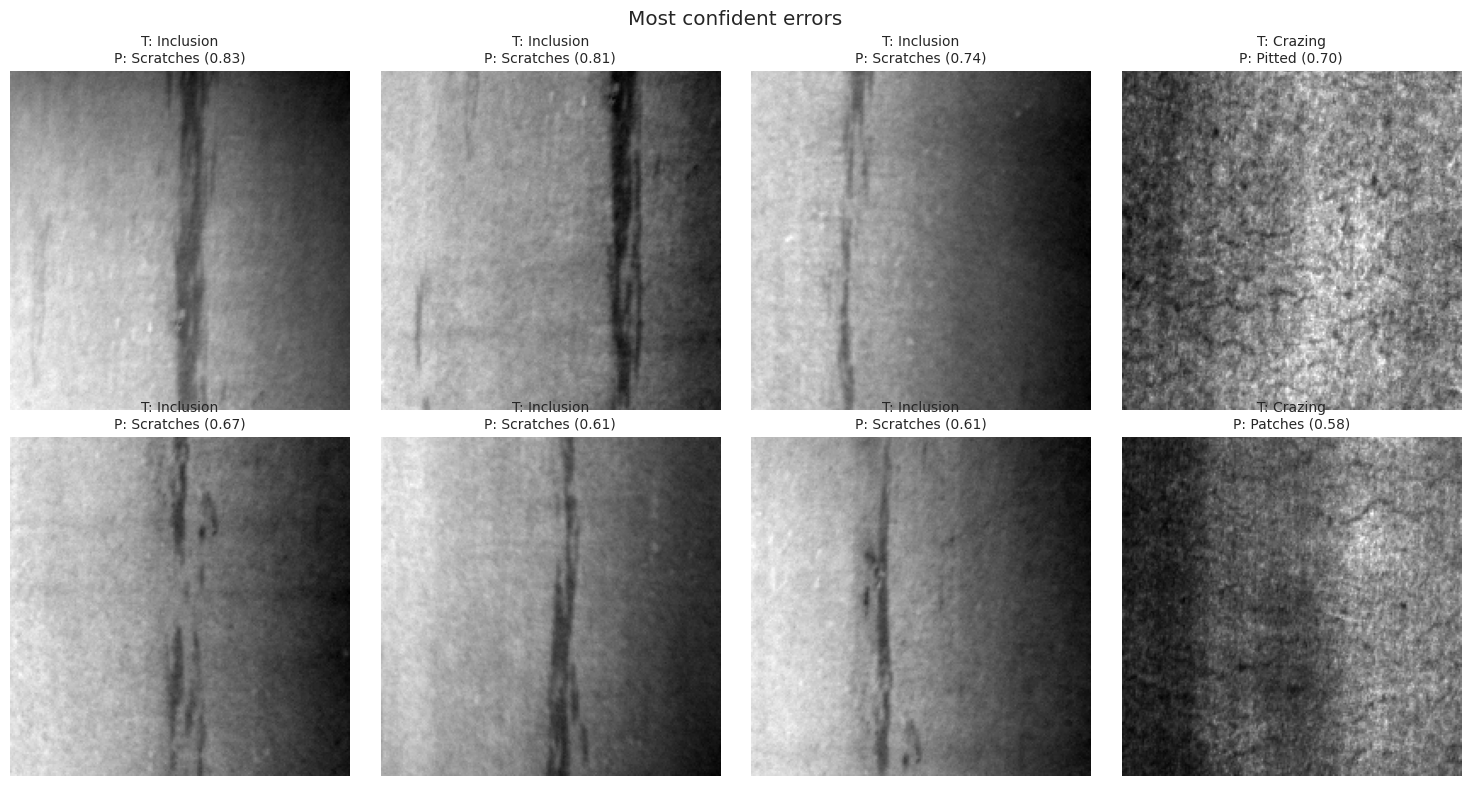

mean confidence | correct: 0.784 | wrong: 0.440


In [9]:
if CV_DONE:
    ea_df, ea_y, ea_proba, ea_src = all_df, all_df.y.values, oof_cnn_proba, "OOF (5-fold)"
else:
    ea_df, ea_y, ea_proba, ea_src = test_df, y_te, cands["CNN softmax (fine-tuned)"][1], "official test"
ea_pred = ea_proba.argmax(1); wrong = np.where(ea_pred != ea_y)[0]
print(f"[{ea_src}] errors: {len(wrong)} / {len(ea_y)}")

pairs = Counter((idx_to_class[ea_y[i]], idx_to_class[ea_pred[i]]) for i in wrong)
pairs_df = pd.DataFrame([{"true": a, "predicted": b, "count": c} for (a, b), c in pairs.most_common()])
print(pairs_df.to_string(index=False) if len(pairs_df) else "No confusions.")
RESULTS["error_analysis"] = {"source": ea_src, "n_errors": int(len(wrong)), "n": int(len(ea_y)), "top_confusions": pairs_df.head(10)}

if len(wrong):
    top = wrong[np.argsort(-ea_proba[wrong].max(1))][:8]
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), top):
        ax.imshow(Image.open(ea_df.filepath.iloc[i]).convert("L"), cmap="gray")
        ax.set_title(f"T: {idx_to_class[ea_y[i]]}\nP: {idx_to_class[ea_pred[i]]} ({ea_proba[i].max():.2f})", fontsize=10)
    plt.suptitle("Most confident errors"); savefig("07_top_errors.png"); plt.show()

    # reliability: is confidence informative about correctness?
    conf = ea_proba.max(1); ok = ea_pred == ea_y
    print(f"mean confidence | correct: {conf[ok].mean():.3f} | wrong: {conf[~ok].mean():.3f}")

## 7. Explainability

* **Grad-CAM** (last conv block of the fine-tuned CNN): *where* in the image does the evidence come from? A defect classifier whose heat-maps sit on the strip border or on a text watermark is a red flag, regardless of accuracy.
* **SHAP** on the XGBoost head: which of the 1 280 embedding dimensions drive the decision. Individual dimensions are abstract — treat SHAP here as a **sanity/stability diagnostic**, and Grad-CAM as the human-readable explanation.

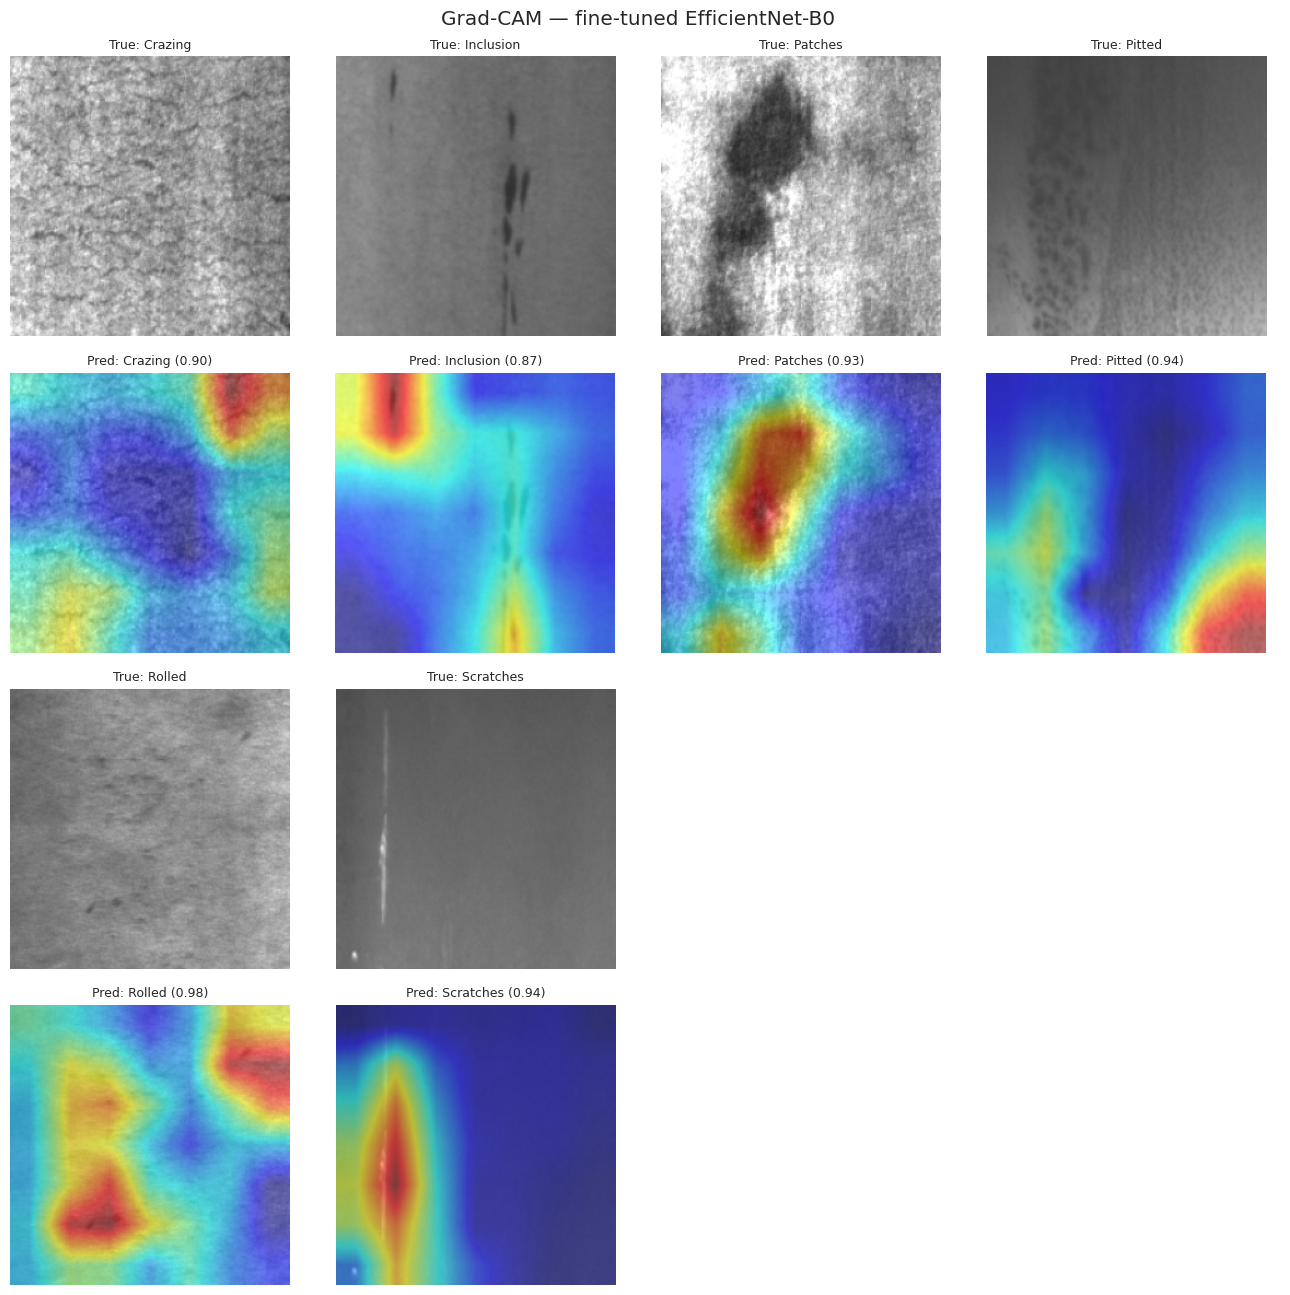

In [10]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

for p_ in model_A.parameters(): p_.requires_grad_(True)
cam = GradCAM(model=model_A, target_layers=[model_A.features[-1]])

def denorm(t):
    return np.clip(t.cpu().numpy().transpose(1, 2, 0) * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN), 0, 1)

def gradcam_overlay(filepath):
    x = eval_tf(Image.open(filepath).convert("RGB")).unsqueeze(0).to(DEVICE)
    with torch.no_grad(): pr = torch.softmax(model_A(x).float(), 1)[0]
    k = int(pr.argmax()); g = cam(input_tensor=x, targets=[ClassifierOutputTarget(k)])[0]
    rgb = denorm(x[0]); return rgb, show_cam_on_image(rgb.astype(np.float32), g, use_rgb=True), k, float(pr[k])

# one test image per class + every misclassified test image (if any)
picks = [test_df[test_df.label == c].filepath.iloc[0] for c in CLASSES]
test_pred_A = cands["CNN softmax (fine-tuned)"][1].argmax(1)
picks += [test_df.filepath.iloc[i] for i in np.where(test_pred_A != y_te)[0][:4]]
cols = 4; rows_ = int(np.ceil(len(picks) / cols))
fig, axes = plt.subplots(rows_ * 2, cols, figsize=(3.3 * cols, 3.3 * rows_ * 2))
for ax in np.ravel(axes): ax.axis("off")
for n_, fp in enumerate(picks):
    rgb, ov, k, c = gradcam_overlay(fp); r_, c_ = divmod(n_, cols)
    true_c = test_df.label[test_df.filepath == fp].iloc[0]
    axes[2 * r_, c_].imshow(rgb); axes[2 * r_, c_].set_title(f"True: {true_c}", fontsize=9)
    axes[2 * r_ + 1, c_].imshow(ov); axes[2 * r_ + 1, c_].set_title(f"Pred: {idx_to_class[k]} ({c:.2f})", fontsize=9)
plt.suptitle("Grad-CAM — fine-tuned EfficientNet-B0"); savefig("08_gradcam.png"); plt.show()

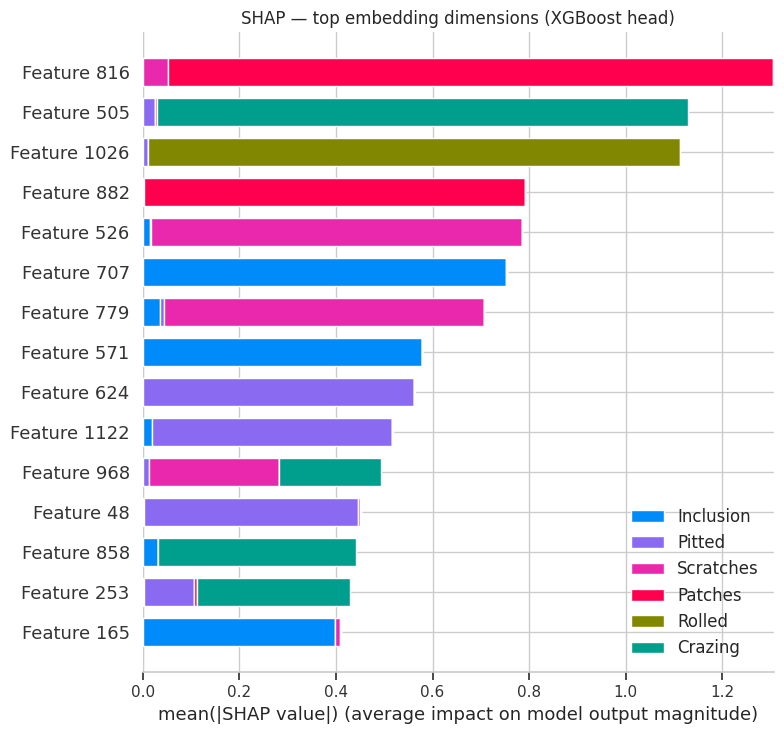

In [11]:
import shap
xgb_A = heads_A["XGBoost"]
Xs = F_te[:CFG.shap_n]
try:
    sv = shap.TreeExplainer(xgb_A).shap_values(Xs)
    shap.summary_plot(sv, Xs, plot_type="bar", class_names=CLASSES, max_display=15, show=False)
    plt.title("SHAP — top embedding dimensions (XGBoost head)"); savefig("09_shap_summary.png"); plt.show()
except Exception as e:
    print("SHAP skipped:", repr(e))

## 8. Robustness and efficiency

A line camera in a mill sees noise, defocus and lighting drift. We perturb the **test images only** (the model never sees perturbed data in training) and track accuracy. Test set is small, so read the curves qualitatively. Then we measure model size and latency.

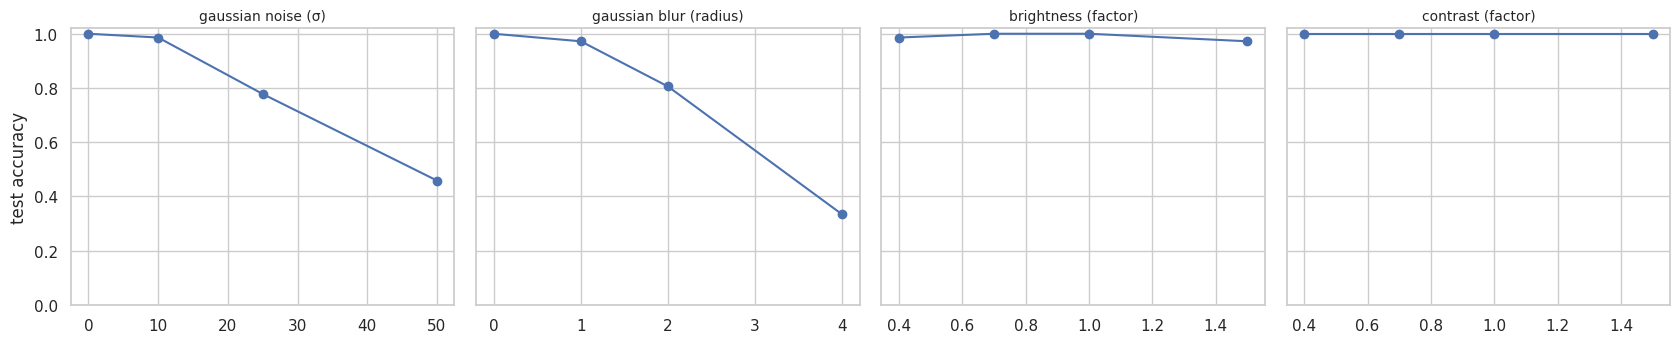

perturbation  brightness (factor)  contrast (factor)  gaussian blur (radius)  gaussian noise (σ)
level                                                                                           
0.0                           NaN                NaN                   1.000               1.000
0.4                         0.986                1.0                     NaN                 NaN
0.7                         1.000                1.0                     NaN                 NaN
1.0                         1.000                1.0                   0.972                 NaN
1.5                         0.972                1.0                     NaN                 NaN
2.0                           NaN                NaN                   0.806                 NaN
4.0                           NaN                NaN                   0.333                 NaN
10.0                          NaN                NaN                     NaN               0.986
25.0                          

In [12]:
rng_noise = np.random.default_rng(0)
def p_noise(s):
    def f(img):
        a = np.asarray(img).astype(np.float32) + rng_noise.normal(0, s, np.asarray(img).shape)
        return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    return f
def p_blur(r): return lambda img: img.filter(ImageFilter.GaussianBlur(r))
def p_bright(f_): return lambda img: ImageEnhance.Brightness(img).enhance(f_)
def p_contrast(f_): return lambda img: ImageEnhance.Contrast(img).enhance(f_)

PERT = {
    "gaussian noise (σ)":  [(0, p_noise(0)), (10, p_noise(10)), (25, p_noise(25)), (50, p_noise(50))],
    "gaussian blur (radius)": [(0, p_blur(0)), (1, p_blur(1)), (2, p_blur(2)), (4, p_blur(4))],
    "brightness (factor)": [(0.4, p_bright(0.4)), (0.7, p_bright(0.7)), (1.0, p_bright(1.0)), (1.5, p_bright(1.5))],
    "contrast (factor)":   [(0.4, p_contrast(0.4)), (0.7, p_contrast(0.7)), (1.0, p_contrast(1.0)), (1.5, p_contrast(1.5))],
}
rob_rows = []
for pname, levels in PERT.items():
    for lvl, fn in levels:
        tf = transforms.Compose([transforms.Lambda(fn), eval_tf])
        acc = accuracy_score(y_te, predict_proba(model_A, test_df, transform=tf).argmax(1))
        rob_rows.append({"perturbation": pname, "level": lvl, "accuracy": acc})
rob_df = pd.DataFrame(rob_rows)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, (pname, d) in zip(axes, rob_df.groupby("perturbation", sort=False)):
    ax.plot(d.level, d.accuracy, "o-"); ax.set_title(pname, fontsize=10); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("test accuracy"); savefig("10_robustness.png"); plt.show()
RESULTS["robustness"] = rob_df
print(rob_df.pivot(index="level", columns="perturbation", values="accuracy").round(3).to_string())

In [13]:
def cls_efficiency(model, n_iter=100):
    x = torch.randn(1, 3, S, S, device=DEVICE); model.eval()
    with torch.no_grad():
        for _ in range(10): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t = time.perf_counter()
        for _ in range(n_iter): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / n_iter * 1000

eff = {"classifier_params_M": sum(p.numel() for p in model_A.parameters()) / 1e6,
       "classifier_size_MB": (OUT / "efficientnet_b0_finetuned.pt").stat().st_size / 1e6,
       "classifier_latency_ms_bs1": cls_efficiency(model_A), "device": str(DEVICE)}
RESULTS["efficiency_classifier"] = eff
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in eff.items()})

{'classifier_params_M': 4.02, 'classifier_size_MB': 16.37, 'classifier_latency_ms_bs1': 7.8, 'device': 'cuda'}


## 9. Detection — YOLOv8 on NEU-DET boxes

The classifier answers *"what defect is on this image?"*. A line operator also needs *"where?"*, so we train a detector on the Pascal-VOC boxes of NEU-DET.

Methodology notes:
* The VOC → YOLO conversion matches each XML to the **closest** image file (same dataset folder) and skips malformed boxes.
* The 80/10/10 split is **stratified by the image's dominant class**; the *val* split drives early stopping and the operating threshold, the *test* split is touched once.
* We report **mAP50, mAP50-95, precision, recall per class**, an **image-level** view (does the top detection match the ground-truth class? how many images get no detection?) and **latency**.

{
  "annotated_images": 1800,
  "boxes_total": 4189,
  "boxes_per_class": {
    "Crazing": 689,
    "Inclusion": 1011,
    "Patches": 881,
    "Pitted": 432,
    "Rolled": 628,
    "Scratches": 548
  },
  "mean_boxes_per_image": 2.3272222222222223,
  "skipped_annotations": {}
}


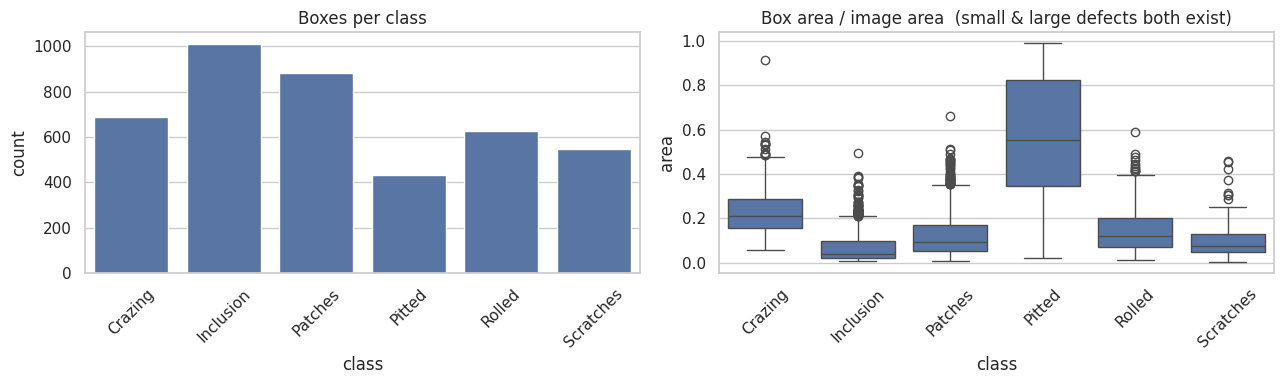

{'train': 1440, 'val': 180, 'test': 180} -> /kaggle/working/yolo_data/data.yaml


In [15]:
import xml.etree.ElementTree as ET
os.environ["WANDB_DISABLED"] = "true"
INPUT_ROOT, YOLO_DIR = "/kaggle/input", OUT / "yolo_data"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

xml_files, img_by_stem = [], {}
for dp, _, fs in os.walk(INPUT_ROOT):
    for f in fs:
        stem, ext = os.path.splitext(f); p = os.path.join(dp, f)
        if ext.lower() == ".xml": xml_files.append(p)
        elif ext.lower() in IMG_EXT: img_by_stem.setdefault(stem, []).append(p)
assert xml_files, "No .xml annotations found: add a NEU-DET dataset version that contains the ANNOTATIONS folder."

def closest_image(xml_path, stem):
    cands_ = img_by_stem.get(stem, [])
    if not cands_: return None
    def score(p):
        try: return len(os.path.commonpath([xml_path, p]))
        except ValueError: return 0
    return max(cands_, key=score)

KEY2IDX = {c[:4].lower(): i for i, c in enumerate(CLASSES)}      # 'pitt' -> Pitted, 'roll' -> Rolled, ...

def parse_voc(xp):
    root = ET.parse(xp).getroot(); size = root.find("size")
    W = float(size.findtext("width", 200)) if size is not None else 200.0
    H = float(size.findtext("height", 200)) if size is not None else 200.0
    W, H = (W or 200.0), (H or 200.0); boxes, skipped = [], Counter()
    for o in root.iter("object"):
        key = o.findtext("name", "").strip().lower()[:4]; bb = o.find("bndbox")
        if key not in KEY2IDX or bb is None: skipped[key] += 1; continue
        x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
        x1, x2, y1, y2 = max(0, x1), min(W, x2), max(0, y1), min(H, y2)
        if x2 <= x1 or y2 <= y1: skipped["degenerate"] += 1; continue
        boxes.append((KEY2IDX[key], x1, y1, x2, y2))
    return W, H, boxes, skipped

samples, seen, skipped_all, box_rows = [], set(), Counter(), []
for xp in sorted(xml_files):
    stem = os.path.splitext(os.path.basename(xp))[0]
    if stem in seen: continue
    img = closest_image(xp, stem)
    if img is None: continue
    W, H, boxes, sk = parse_voc(xp); skipped_all.update(sk)
    if not boxes: continue
    seen.add(stem)
    lines = [f"{c} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}" for c, x1, y1, x2, y2 in boxes]
    for c, x1, y1, x2, y2 in boxes: box_rows.append({"class": CLASSES[c], "w": (x2-x1)/W, "h": (y2-y1)/H, "area": (x2-x1)*(y2-y1)/(W*H)})
    samples.append({"stem": stem, "img": img, "lines": lines, "dom": Counter(b[0] for b in boxes).most_common(1)[0][0], "n_boxes": len(boxes)})

boxes_df = pd.DataFrame(box_rows)
det_data = {"annotated_images": len(samples), "boxes_total": int(len(boxes_df)),
            "boxes_per_class": boxes_df["class"].value_counts().sort_index().to_dict(),
            "mean_boxes_per_image": float(np.mean([s["n_boxes"] for s in samples])),
            "skipped_annotations": dict(skipped_all)}
RESULTS["detection_data"] = det_data; print(json.dumps(jsonable(det_data), indent=2))
assert len(samples) > 100, "Too few matched image/xml pairs."

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=boxes_df, x="class", order=CLASSES, ax=ax[0]); ax[0].set_title("Boxes per class"); ax[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=boxes_df, x="class", y="area", order=CLASSES, ax=ax[1]); ax[1].set_title("Box area / image area  (small & large defects both exist)"); ax[1].tick_params(axis="x", rotation=45)
savefig("11_detection_data.png"); plt.show()

# ---- stratified 80/10/10 split by dominant class ----
idx_all = np.arange(len(samples)); dom = np.array([s["dom"] for s in samples])
tr_i, tmp_i = train_test_split(idx_all, test_size=0.2, stratify=dom, random_state=SEED)
va_i, te_i = train_test_split(tmp_i, test_size=0.5, stratify=dom[tmp_i], random_state=SEED)
splits = {"train": tr_i, "val": va_i, "test": te_i}

shutil.rmtree(YOLO_DIR, ignore_errors=True)
for split, ids in splits.items():
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True); (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)
    for i in ids:
        s_ = samples[i]
        shutil.copy(s_["img"], YOLO_DIR / "images" / split / f"{s_['stem']}{os.path.splitext(s_['img'])[1]}")
        (YOLO_DIR / "labels" / split / f"{s_['stem']}.txt").write_text("\n".join(s_["lines"]))

yaml_path = str(YOLO_DIR / "data.yaml")
with open(yaml_path, "w") as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n")
    f.write("\n".join(f"  {i}: {c}" for i, c in enumerate(CLASSES)))
print({k: len(v) for k, v in splits.items()}, "->", yaml_path)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=

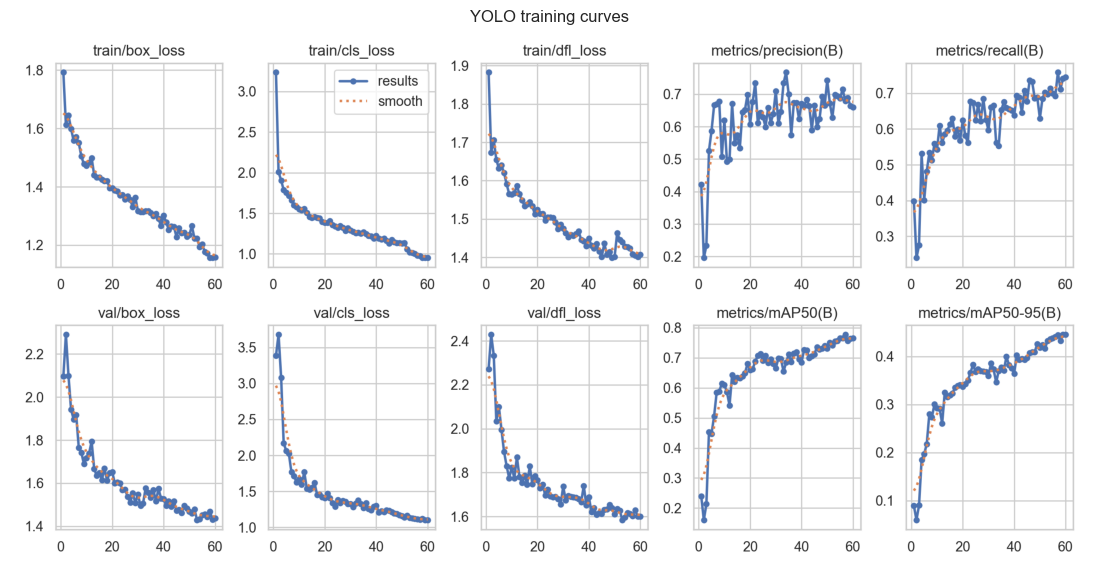

In [16]:
from ultralytics import YOLO

t0 = time.time()
yolo = YOLO(CFG.yolo_model)
yolo.train(data=yaml_path, epochs=CFG.yolo_epochs, imgsz=CFG.yolo_imgsz, batch=CFG.yolo_batch, patience=CFG.yolo_patience,
           seed=SEED, project=str(OUT / "runs"), name="neu_yolo", exist_ok=True, plots=True, verbose=False)
BEST = str(yolo.trainer.best)
RESULTS["yolo_train_time_sec"] = round(time.time() - t0, 1)
print("Best weights:", BEST)

res_png = Path(BEST).parent.parent / "results.png"
if res_png.exists():
    plt.figure(figsize=(14, 7)); plt.imshow(Image.open(res_png)); plt.axis("off"); plt.title("YOLO training curves"); plt.show()

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 673.1±308.2 MB/s, size: 15.4 KB)
val: Scanning /kaggle/working/yolo_data/labels/val.cache... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 62.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 7.7it/s 1.6s0.1s
                   all        180        412      0.661      0.745      0.765      0.446
Speed: 0.9ms preprocess, 4.2ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 567.1±260.6 MB/s, size: 14.2 KB)
val: Scanning /kaggle/working/yolo_data/labels/test... 180 images

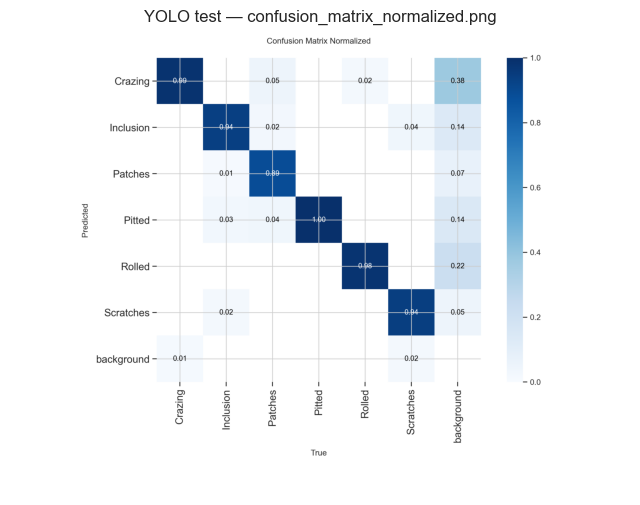

In [17]:
best_det = YOLO(BEST)
def run_val(split):
    return best_det.val(data=yaml_path, split=split, imgsz=CFG.yolo_imgsz, plots=(split == "test"), verbose=False,
                        project=str(OUT / "runs"), name=f"val_{split}", exist_ok=True)

m_val, m_test = run_val("val"), run_val("test")

def det_table(m):
    rows = []
    for k, ci in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(k)
        rows.append({"class": CLASSES[int(ci)], "precision": p, "recall": r, "AP50": ap50, "AP50-95": ap})
    return pd.DataFrame(rows)

det_val_tbl, det_test_tbl = det_table(m_val), det_table(m_test)
det_overall = {"val_mAP50": float(m_val.box.map50), "val_mAP50_95": float(m_val.box.map),
               "test_mAP50": float(m_test.box.map50), "test_mAP50_95": float(m_test.box.map),
               "test_precision": float(m_test.box.mp), "test_recall": float(m_test.box.mr),
               "n_test_images": len(splits["test"])}
print(json.dumps(det_overall, indent=2)); print("\nPer-class (TEST):\n", det_test_tbl.round(3).to_string(index=False))

# operating confidence threshold = argmax of mean F1 curve on VALIDATION
try:
    OP_CONF = float(np.asarray(m_val.box.px)[np.argmax(np.asarray(m_val.box.f1_curve).mean(0))])
except Exception as e:
    print("F1-curve unavailable (", repr(e), ") -> default 0.25"); OP_CONF = 0.25
det_overall["operating_conf_from_val"] = OP_CONF; print(f"Operating confidence (picked on val): {OP_CONF:.3f}")

for name in ("confusion_matrix_normalized.png", "PR_curve.png"):
    pth = OUT / "runs" / "val_test" / name
    if pth.exists():
        plt.figure(figsize=(8, 7)); plt.imshow(Image.open(pth)); plt.axis("off"); plt.title(f"YOLO test — {name}"); plt.show()

# latency / size
det_overall.update({"speed_ms_per_image": {k: float(v) for k, v in m_test.speed.items()},
                    "params_M": sum(p.numel() for p in best_det.model.parameters()) / 1e6,
                    "weights_MB": Path(BEST).stat().st_size / 1e6})
RESULTS["detection"] = {"overall": det_overall, "per_class_test": det_test_tbl, "per_class_val": det_val_tbl}

image-level accuracy (top detection vs GT dominant class): 0.956 | images with NO detection: 0.039


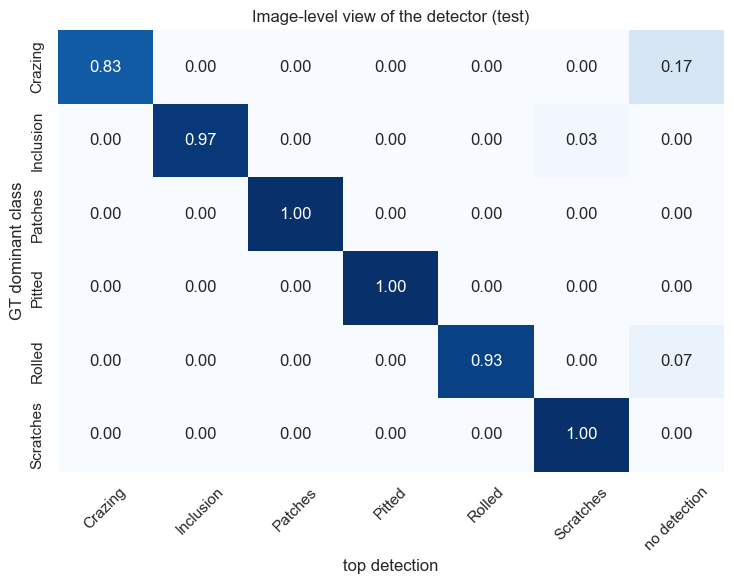

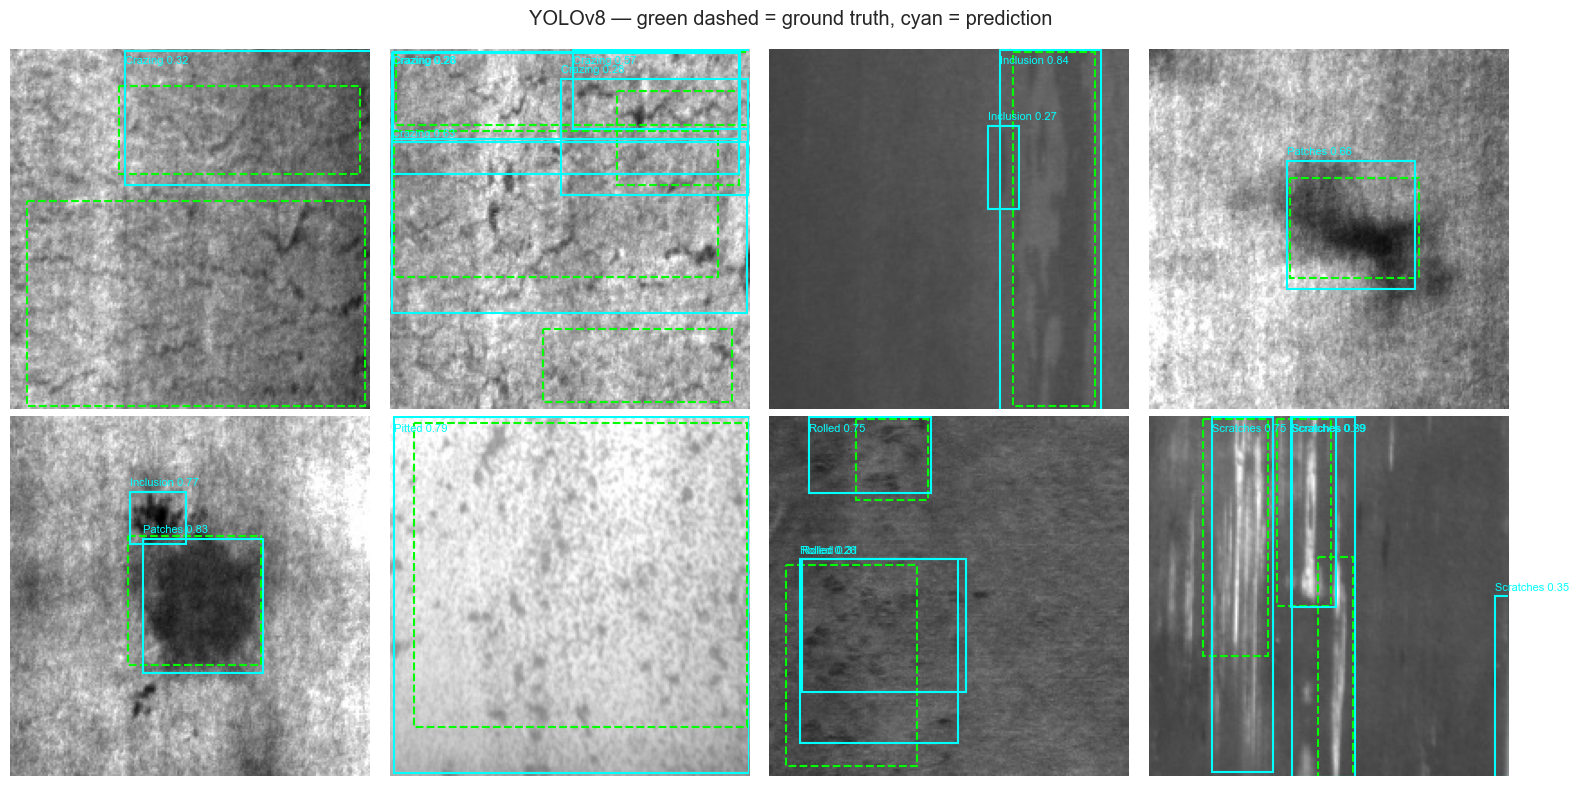

In [18]:
# ---- image-level view on the held-out test split ----
def gt_boxes(label_file, W, H):
    out = []
    for ln in Path(label_file).read_text().strip().splitlines():
        c, x, y, w, h = ln.split(); c = int(c); x, y, w, h = float(x) * W, float(y) * H, float(w) * W, float(h) * H
        out.append((c, x - w / 2, y - h / 2, x + w / 2, y + h / 2))
    return out

test_imgs = sorted(glob.glob(str(YOLO_DIR / "images" / "test" / "*")))
gt_dom = []
for p in test_imgs:
    lab = YOLO_DIR / "labels" / "test" / f"{Path(p).stem}.txt"
    gt_dom.append(Counter(int(l.split()[0]) for l in lab.read_text().strip().splitlines()).most_common(1)[0][0])
gt_dom = np.array(gt_dom)

preds_det = best_det.predict(test_imgs, imgsz=CFG.yolo_imgsz, conf=OP_CONF, verbose=False)
top_cls = np.array([int(r.boxes.cls[r.boxes.conf.argmax()]) if len(r.boxes) else -1 for r in preds_det])
no_det = float((top_cls == -1).mean()); img_acc = float((top_cls == gt_dom).mean())
print(f"image-level accuracy (top detection vs GT dominant class): {img_acc:.3f} | images with NO detection: {no_det:.3f}")

lab_names = CLASSES + ["no detection"]; top_plot = np.where(top_cls == -1, NUM_CLASSES, top_cls)
cm = confusion_matrix(gt_dom, top_plot, labels=list(range(NUM_CLASSES + 1)))[:NUM_CLASSES]
cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7.5, 6)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=lab_names, yticklabels=CLASSES, cbar=False, ax=ax)
ax.set_xlabel("top detection"); ax.set_ylabel("GT dominant class"); ax.set_title("Image-level view of the detector (test)"); plt.xticks(rotation=45)
savefig("12_yolo_image_level.png"); plt.show()
RESULTS["detection"]["image_level"] = {"accuracy_top_detection": img_acc, "no_detection_rate": no_det, "conf": OP_CONF}

# ---- qualitative: ground truth (green) vs prediction (cyan) ----
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, p, r in zip(axes.ravel(), test_imgs[::max(len(test_imgs) // 8, 1)][:8], preds_det[::max(len(test_imgs) // 8, 1)][:8]):
    img = Image.open(p).convert("RGB"); W, H = img.size; ax.imshow(img); ax.axis("off")
    for c, x1, y1, x2, y2 in gt_boxes(YOLO_DIR / "labels" / "test" / f"{Path(p).stem}.txt", W, H):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=1.5, ls="--"))
    for b, c, cf in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls, r.boxes.conf):
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="cyan", lw=1.5))
        ax.text(b[0], max(b[1] - 3, 8), f"{CLASSES[int(c)]} {float(cf):.2f}", color="cyan", fontsize=8)
plt.suptitle("YOLOv8 — green dashed = ground truth, cyan = prediction"); savefig("13_yolo_qualitative.png"); plt.show()

## 10. Segmentation — SAM2 (boxes → masks)

NEU-DET has **no ground-truth masks**, so mask IoU / Dice **cannot be computed honestly**. Instead we report *proxy* quality metrics that catch gross failures and say so explicitly:

* `mask/box area ratio` — a mask that fills ≈ 0 % or ≈ 100 % of its box is suspicious,
* `containment` — share of mask pixels that fall inside the prompting box (SAM may legitimately extend slightly beyond),
* `empty-mask rate` and **latency** (SAM is much heavier than YOLO → this motivates the two-tier design: SAM only runs when the detector fires).

For a real segmentation score, annotate ~50 test masks (e.g. in CVAT / Label Studio) and compute IoU/Dice against them.

{
  "n_masks": 164,
  "empty_mask_rate": 0.0,
  "mask_box_ratio_median": 0.5541123999457334,
  "mask_box_ratio_p10": 0.33311117780752225,
  "mask_box_ratio_p90": 0.793596474953618,
  "containment_median": 1.0,
  "sam_latency_ms_per_image": 160.0621996727403,
  "images_evaluated": 55,
  "note": "Proxy metrics only - no ground-truth masks available"
}


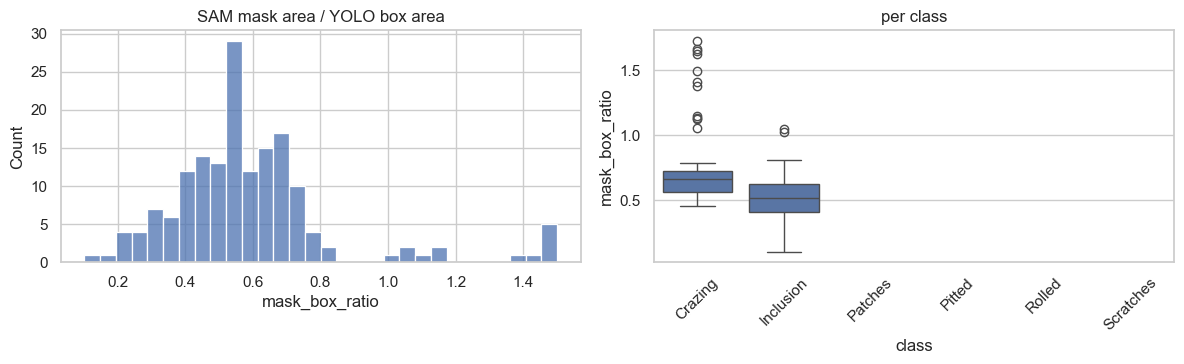

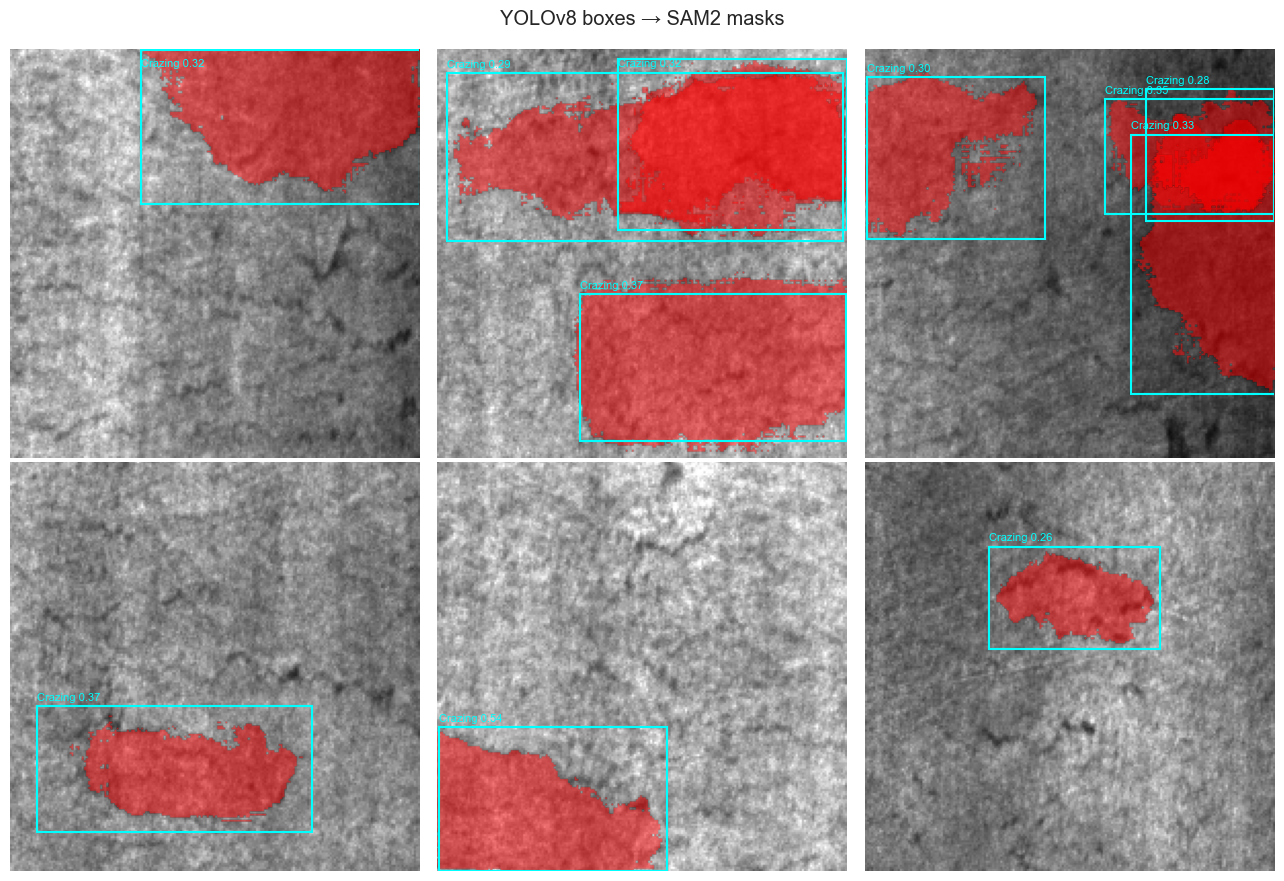

In [20]:
from ultralytics import SAM
sam = SAM(CFG.sam_weights)

def sam_masks_for(path, boxes_xyxy, size):
    res = sam(path, bboxes=boxes_xyxy.tolist(), verbose=False)[0]
    if res.masks is None: return np.zeros((0, size[1], size[0]), bool)
    ms = res.masks.data.cpu().numpy()
    return np.stack([np.array(Image.fromarray((m * 255).astype(np.uint8)).resize(size)) > 127 for m in ms])

sam_rows, sam_times, shown = [], [], []
for p, r in zip(test_imgs[:CFG.sam_eval_images], preds_det[:CFG.sam_eval_images]):
    if len(r.boxes) == 0: continue
    img = Image.open(p).convert("RGB"); boxes = r.boxes.xyxy.cpu().numpy()
    t = time.perf_counter(); masks = sam_masks_for(p, boxes, img.size); sam_times.append((time.perf_counter() - t) * 1000)
    for b, m, c in zip(boxes, masks, r.boxes.cls):
        x1, y1, x2, y2 = [int(round(v)) for v in b]; box_area = max((x2 - x1) * (y2 - y1), 1); area = int(m.sum())
        inside = int(m[max(y1, 0):y2, max(x1, 0):x2].sum())
        sam_rows.append({"class": CLASSES[int(c)], "mask_box_ratio": area / box_area, "containment": inside / area if area else np.nan, "empty": area == 0})
    if len(shown) < 6: shown.append((img, boxes, masks, r))


sam_df = pd.DataFrame(sam_rows)

sam_summary = {
    "n_masks": int(len(sam_df)),
    "empty_mask_rate": (
        float(sam_df["empty"].mean()) if not sam_df.empty else None
    ),
    "mask_box_ratio_median": (
        float(sam_df["mask_box_ratio"].median())
        if not sam_df.empty else None
    ),
    "mask_box_ratio_p10": (
        float(sam_df["mask_box_ratio"].quantile(0.1))
        if not sam_df.empty else None
    ),
    "mask_box_ratio_p90": (
        float(sam_df["mask_box_ratio"].quantile(0.9))
        if not sam_df.empty else None
    ),
    "containment_median": (
        float(sam_df["containment"].median())
        if not sam_df.empty else None
    ),
    "sam_latency_ms_per_image": (
        float(np.mean(sam_times)) if sam_times else None
    ),
    "images_evaluated": len(sam_times),
    "note": "Proxy metrics only - no ground-truth masks available"
}

RESULTS["segmentation_proxy"] = sam_summary
print(json.dumps(jsonable(sam_summary), indent=2))


fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(sam_df.mask_box_ratio.clip(0, 1.5), bins=30, ax=ax[0]); ax[0].set_title("SAM mask area / YOLO box area")
sns.boxplot(data=sam_df, x="class", y="mask_box_ratio", order=CLASSES, ax=ax[1]); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("per class")
savefig("14_sam_proxy.png"); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, (img, boxes, masks, r) in zip(axes.ravel(), shown):
    ax.imshow(img); ax.axis("off")
    for b, m, c, cf in zip(boxes, masks, r.boxes.cls, r.boxes.conf):
        ax.imshow(np.ma.masked_where(~m, m), alpha=.5, cmap="autumn")
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="cyan", lw=1.5))
        ax.text(b[0], max(b[1] - 3, 8), f"{CLASSES[int(c)]} {float(cf):.2f}", color="cyan", fontsize=8)
plt.suptitle("YOLOv8 boxes → SAM2 masks"); savefig("15_sam_qualitative.png"); plt.show()

## 11. End-to-end inspection function (the logic the web demo / API reproduces)

`image → YOLO boxes → (if any) SAM2 masks → image-level classifier + Grad-CAM + XGBoost probabilities`.
The classifier and the detector are trained on different splits of the same 1 800 images, so **do not use the agreement between them as an accuracy metric** — it is a demo of the two-tier architecture, not an evaluation.

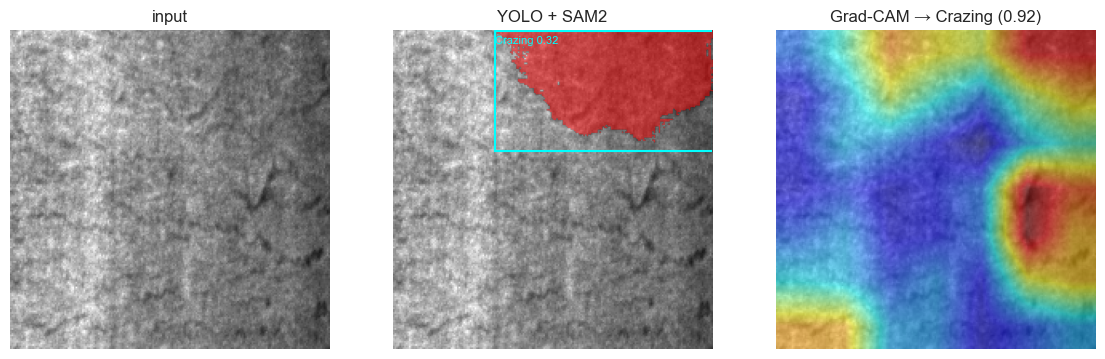

{
  "file": "crazing_10.jpg",
  "n_defects_detected": 1,
  "classifier_xgboost": {
    "Crazing": 0.9991,
    "Inclusion": 0.0001,
    "Patches": 0.0002,
    "Pitted": 0.0003,
    "Rolled": 0.0002,
    "Scratches": 0.0001
  },
  "detections": [
    {
      "class": "Crazing",
      "confidence": 0.316,
      "box_xyxy": [
        63.6,
        0.5,
        200.0,
        75.4
      ],
      "mask_area_px": 6889
    }
  ],
  "total_ms": 176.6
}


In [23]:
@torch.no_grad()
def _embed(x): return ex_A(x).float().cpu().numpy()

def inspect_image(path, conf=None, draw=True):
    conf = OP_CONF if conf is None else conf; t0 = time.perf_counter()
    img = Image.open(path).convert("RGB"); W, H = img.size
    det = best_det.predict(path, imgsz=CFG.yolo_imgsz, conf=conf, verbose=False)[0]
    boxes = det.boxes.xyxy.cpu().numpy(); masks = sam_masks_for(path, boxes, img.size) if len(boxes) else []
    x = eval_tf(img).unsqueeze(0).to(DEVICE)
    cls_proba = xgb_A.predict_proba(_embed(x))[0]
    out = {"file": os.path.basename(path), "n_defects_detected": int(len(boxes)),
           "classifier_xgboost": {CLASSES[i]: round(float(p), 4) for i, p in enumerate(cls_proba)},
           "detections": [{"class": CLASSES[int(c)], "confidence": round(float(cf), 3), "box_xyxy": [round(float(v), 1) for v in b],
                           "mask_area_px": int(m.sum())} for b, m, c, cf in zip(boxes, masks if len(boxes) else [], det.boxes.cls, det.boxes.conf)],
           "total_ms": round((time.perf_counter() - t0) * 1000, 1)}
    if draw:
        rgb, ov, k, c = gradcam_overlay(path)
        fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
        ax[0].imshow(img); ax[0].set_title("input")
        ax[1].imshow(img)
        for b, m, c_, cf in zip(boxes, masks if len(boxes) else [], det.boxes.cls, det.boxes.conf):
            ax[1].imshow(np.ma.masked_where(~m, m), alpha=.5, cmap="autumn")
            ax[1].add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="cyan", lw=1.5))
            ax[1].text(b[0], max(b[1]-3, 8), f"{CLASSES[int(c_)]} {float(cf):.2f}", color="cyan", fontsize=8)
        ax[1].set_title("YOLO + SAM2"); ax[2].imshow(ov); ax[2].set_title(f"Grad-CAM → {idx_to_class[k]} ({c:.2f})")
        for a in ax: a.axis("off")
        plt.show()
    return out

demo = inspect_image(test_imgs[0]); print(json.dumps(demo, indent=2))

## 12. Deployment bundle

Everything the FastAPI backend needs, in one folder + zip: classifier weights, XGBoost head (`xgb_model.pkl`, same filename as the existing demo expects), the head selected on validation (`head_best.pkl`), class names, YOLO and SAM2 weights, the config and the final metrics.

In [24]:
import joblib
DEP = OUT / "deployment"; shutil.rmtree(DEP, ignore_errors=True); DEP.mkdir(parents=True)

torch.save(model_A.state_dict(), DEP / "efficientnet_b0_finetuned.pt")
joblib.dump(xgb_A, DEP / "xgb_model.pkl")
best_head_name = SELECTED_A.replace("FT-CNN + ", "")
if best_head_name in heads_A: joblib.dump(heads_A[best_head_name], DEP / "head_best.pkl")
(DEP / "classes.json").write_text(json.dumps(CLASSES))
shutil.copy(BEST, DEP / "yolo_best.pt")

try:
    from ultralytics.utils import SETTINGS
    sam_c = []
    for base_ in (".", str(OUT), SETTINGS.get("weights_dir", "."), "/root"):
        sam_c += glob.glob(os.path.join(base_, "**", CFG.sam_weights), recursive=True)
    if sam_c: shutil.copy(sam_c[0], DEP / CFG.sam_weights)
    else: print("SAM2 weights not found locally: the backend downloads them on first run.")
except Exception as e:
    print("SAM2 copy skipped:", repr(e))

(DEP / "config.json").write_text(json.dumps({"classes": CLASSES, "img_size": CFG.img_size, "imagenet_mean": IMAGENET_MEAN,
        "imagenet_std": IMAGENET_STD, "yolo_conf": OP_CONF, "yolo_imgsz": CFG.yolo_imgsz, "selected_head_on_val": SELECTED_A}, indent=2))
(DEP / "versions.json").write_text(json.dumps({"python": platform.python_version(), "torch": torch.__version__,
        "torchvision": __import__("torchvision").__version__, "sklearn": __import__("sklearn").__version__,
        "xgboost": __import__("xgboost").__version__, "ultralytics": __import__("ultralytics").__version__}, indent=2))
(OUT / "results.json").write_text(json.dumps(jsonable(RESULTS), indent=2)); shutil.copy(OUT / "results.json", DEP / "metrics.json")
shutil.make_archive(str(OUT / "deployment"), "zip", str(DEP))

print("deployment/ contains:")
for f in sorted(os.listdir(DEP)): print(f"  {f:<34}{os.path.getsize(DEP / f) / 1e6:8.2f} MB")

deployment/ contains:
  classes.json                          0.00 MB
  config.json                           0.00 MB
  efficientnet_b0_finetuned.pt         16.37 MB
  head_best.pkl                         0.09 MB
  metrics.json                          0.01 MB
  sam2.1_t.pt                          78.11 MB
  versions.json                         0.00 MB
  xgb_model.pkl                         1.78 MB
  yolo_best.pt                          6.51 MB


## 13. Final report (auto-generated from `RESULTS` — no hand-typed numbers)

In [31]:
def fmt(v, d=3): return "n/a" if v is None or (isinstance(v, float) and np.isnan(v)) else f"{v:.{d}f}"
L = ["# Results summary", ""]

o = official_df.loc[SELECTED_A]
L += ["## Classification (6 classes, 1 800 images)",
      f"* **Official split** (selected on validation: *{SELECTED_A}*): test acc {fmt(o.test_acc)} "
      f"(95 % CI {fmt(o.test_acc_CI95_lo)}–{fmt(o.test_acc_CI95_hi)}), macro-F1 {fmt(o.test_macro_f1)} on **{len(y_te)} images** — high variance, read with care.",
      f"* Frozen-ImageNet + LogReg baseline: test acc {fmt(official_df.loc[BASELINE_NAME].test_acc)} → fine-tuning gain = "
      f"{100 * (o.test_acc - official_df.loc[BASELINE_NAME].test_acc):+.1f} pts (on the same tiny test set)."]
if CV_DONE:
    b = cv_summary.loc[BEST_CV]; c = cv_summary.loc["CNN softmax (fine-tuned)"]
    L += [f"* **Leak-free nested {CFG.n_folds}-fold CV (headline)**: best = *{BEST_CV}*, macro-F1 {fmt(b.macro_f1_mean)} ± {fmt(b.macro_f1_std)}, "
          f"accuracy {fmt(b.accuracy_mean)} ± {fmt(b.accuracy_std)} (pooled OOF 95 % CI {fmt(b.oof_acc_CI95_lo)}–{fmt(b.oof_acc_CI95_hi)}).",
          f"* CNN softmax in CV: macro-F1 {fmt(c.macro_f1_mean)} ± {fmt(c.macro_f1_std)}; ECE {fmt(RESULTS['nested_cv']['cnn_softmax_oof_ece'], 4)}.",
          "* Paired McNemar p-values vs CNN softmax: " + "; ".join(f"{r.vs}: p={fmt(r.mcnemar_p)}" for r in mcnemar_df.itertuples()) + "."]
d = RESULTS["detection"]["overall"]; il = RESULTS["detection"]["image_level"]; sp = RESULTS["segmentation_proxy"]
L += ["", "## Detection — YOLOv8 (test split, never used for tuning)",
      f"* mAP50 **{fmt(d['test_mAP50'])}**, mAP50-95 **{fmt(d['test_mAP50_95'])}**, precision {fmt(d['test_precision'])}, recall {fmt(d['test_recall'])} (operating conf {fmt(d['operating_conf_from_val'])} chosen on validation).",
      f"* Weakest class (AP50-95): **{det_test_tbl.sort_values('AP50-95').iloc[0]['class']}** ({fmt(det_test_tbl['AP50-95'].min())}); strongest: **{det_test_tbl.sort_values('AP50-95').iloc[-1]['class']}** ({fmt(det_test_tbl['AP50-95'].max())}).",
      f"* Image-level accuracy {fmt(il['accuracy_top_detection'])}; images with no detection {fmt(il['no_detection_rate'])}.",
      f"* Latency: {', '.join(f'{k} {v:.1f} ms' for k, v in d['speed_ms_per_image'].items())} per image ({d['params_M']:.1f} M params, {d['weights_MB']:.1f} MB).",
      "", "## Segmentation — SAM2 (proxy metrics, no GT masks)",
      f"* median mask/box area {fmt(sp['mask_box_ratio_median'])} (p10–p90: {fmt(sp['mask_box_ratio_p10'])}–{fmt(sp['mask_box_ratio_p90'])}), empty masks {fmt(sp['empty_mask_rate'])}, SAM latency ≈ {sp['sam_latency_ms_per_image']:.0f} ms/image.",
      "", "## Efficiency (classifier)",
      f"* {eff['classifier_params_M']:.1f} M params, {eff['classifier_size_MB']:.1f} MB, {eff['classifier_latency_ms_bs1']:.1f} ms/img (batch 1, {eff['device']})."]
(OUT / "RESULTS_SUMMARY.md").write_text("\n".join(L)); print("\n".join(L))

# Results summary

## Classification (6 classes, 1 800 images)
* **Official split** (selected on validation: *FT-CNN + LogReg*): test acc 1.000 (95 % CI 1.000–1.000), macro-F1 1.000 on **72 images** — high variance, read with care.
* Frozen-ImageNet + LogReg baseline: test acc 1.000 → fine-tuning gain = +0.0 pts (on the same tiny test set).
* **Leak-free nested 5-fold CV (headline)**: best = *FT-CNN + LogReg*, macro-F1 0.999 ± 0.002, accuracy 0.999 ± 0.002 (pooled OOF 95 % CI 0.997–1.000).
* CNN softmax in CV: macro-F1 0.973 ± 0.007; ECE 0.1991.
* Paired McNemar p-values vs CNN softmax: ImageNet-frozen + LogReg: p=0.000; FT-CNN + LogReg: p=0.000; FT-CNN + RandomForest: p=0.000; FT-CNN + XGBoost: p=0.000.

## Detection — YOLOv8 (test split, never used for tuning)
* mAP50 **0.758**, mAP50-95 **0.444**, precision 0.701, recall 0.708 (operating conf 0.244 chosen on validation).
* Weakest class (AP50-95): **Crazing** (0.161); strongest: **Patches** (0.648).
* Image-level accuracy 0.956; ima

## 14. Limitations, threats to validity and next steps

**Limitations (stated up-front on purpose)**
* **Small, clean, single-source dataset** (NEU-DET: 1 800 images of 200×200, 300 per class, one lab setup). High scores here do **not** imply field performance; domain shift (new camera, lighting, steel grade) is untested beyond the synthetic perturbations in §8.
* **Heads are trained on embeddings of images the backbone was fine-tuned on** (train-set features are "easier" than unseen ones). A cleaner stacking scheme would fit heads on out-of-fold embeddings.
* **No ground-truth masks** → SAM2 quality is assessed with proxies only.
* The official 72-image test split cannot separate models that differ by < 5 pts; the nested CV is the number to quote.
* **Image-level classifier vs. detector** are trained on different splits of the same images, so their agreement is not an independent measure.
* SHAP on 1 280 abstract embedding dimensions is a diagnostic, not a human explanation.

**Next steps (ordered by expected value)**
1. Evaluate on a *second* steel dataset (e.g. Severstal / GC10-DET) without retraining → real domain-shift number.
2. Hard-example analysis on *Crazing* (typically the weakest AP): label-noise audit, larger input size / tiling, stronger detector (YOLOv8s/m, RT-DETR).
3. Hand-label ~50 masks → IoU/Dice for SAM2; try SAM2 prompt refinement (box + positive point).
4. Export to ONNX/TensorRT and report end-to-end latency on the target edge device; add conformal prediction / abstention for low-confidence cases.
5. Production concerns: drift monitoring, active-learning loop for rare defects, cost-weighted metrics (a missed *Inclusion* ≠ a false alarm on *Scratches*).